# The Problem

    Given some data about a set of customers' credit card usage details, can we identify groups in them to determine best strategy for cross/up-selling services?


In [1]:
import pandas as pd
import numpy as np
pd.set_option('display.max_columns',30)
pd.set_option('display.max_rows',100)


import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans, SpectralClustering 
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest

In [2]:
cc_data = pd.read_csv('CC GENERAL.csv')

    The idea is to define marketing strategy by developing models for customer segmentation. This is a summary of the usage behavior of about 9000 active credit card holders during the last 6 months. Each row in the csv pertains to one customer.

#### Data Description
    
    CUST_ID : Identification of Credit Card holder (Categorical) 
    BALANCE : Balance amount left in their account to make purchases  
    BALANCE_FREQUENCY : How frequently the Balance is updated, score between 0 and 1 (1 = frequently updated, 0 = not frequently updated )
    PURCHASES : Amount of purchases made from account 
    ONEOFF_PURCHASES : Maximum purchase amount done in one-go 
    INSTALLMENTS_PURCHASES : Amount of purchase done in installment 
    CASH_ADVANCE : Cash in advance given by the user 
    PURCHASES_FREQUENCY : How frequently the Purchases are being made, score between 0 and 1 (1 = frequently purchased, 0 = not frequently purchased) 
    ONEOFFPURCHASESFREQUENCY : How frequently Purchases are happening in one-go (1 = frequently purchased, 0 = not frequently purchased) 
    PURCHASESINSTALLMENTSFREQUENCY : How frequently purchases in installments are being done (1 = frequently done, 0 = not frequently done) 
    CASHADVANCEFREQUENCY : How frequently the cash in advance being paid 
    CASHADVANCETRX : Number of Transactions made with "Cash in Advanced" 
    PURCHASES_TRX : Numbe of purchase transactions made 
    CREDIT_LIMIT : Limit of Credit Card for user 
    PAYMENTS : Amount of Payment done by user 
    MINIMUM_PAYMENTS : Minimum amount of payments made by user 
    PRCFULLPAYMENT : Percent of full payment paid by user 
    TENURE : Tenure of credit card service for user

In [3]:
cc_data.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [4]:
cc_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
CUST_ID                             8950 non-null object
BALANCE                             8950 non-null float64
BALANCE_FREQUENCY                   8950 non-null float64
PURCHASES                           8950 non-null float64
ONEOFF_PURCHASES                    8950 non-null float64
INSTALLMENTS_PURCHASES              8950 non-null float64
CASH_ADVANCE                        8950 non-null float64
PURCHASES_FREQUENCY                 8950 non-null float64
ONEOFF_PURCHASES_FREQUENCY          8950 non-null float64
PURCHASES_INSTALLMENTS_FREQUENCY    8950 non-null float64
CASH_ADVANCE_FREQUENCY              8950 non-null float64
CASH_ADVANCE_TRX                    8950 non-null int64
PURCHASES_TRX                       8950 non-null int64
CREDIT_LIMIT                        8949 non-null float64
PAYMENTS                            8950 non-null float64
MINIMUM_PAYMENTS            

In [5]:
cc_data.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


    There are 18 columns, 8950 rows, 314 null values overall and only the id column is categorical. All other columns are unscaled positive real numbers

In [6]:
sum(cc_data.duplicated())
#No duplicates
sum(cc_data['CUST_ID'].duplicated())
#No repeated customers
cc_data['CREDIT_LIMIT'].isna().sum()
#1 null value
cc_data['MINIMUM_PAYMENTS'].isna().sum()
#313 null values

313

In [7]:
cc_data.loc[np.where(cc_data['CREDIT_LIMIT'].isna())[0],:]

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
5203,C15349,18.400472,0.166667,0.0,0.0,0.0,186.853063,0.0,0.0,0.0,0.166667,1,0,NaN,9.040017,14.418723,0.0,6


In [8]:
cc_data.loc[np.where(cc_data['MINIMUM_PAYMENTS'].isna())[0],:]

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.0,12
45,C10047,2242.311686,1.000000,437.00,97.00,340.0,184.648692,0.333333,0.083333,0.333333,0.166667,2,5,2400.0,0.000000,NaN,0.0,12
47,C10049,3910.111237,1.000000,0.00,0.00,0.0,1980.873201,0.000000,0.000000,0.000000,0.500000,7,0,4200.0,0.000000,NaN,0.0,12
54,C10056,6.660517,0.636364,310.00,0.00,310.0,0.000000,0.666667,0.000000,0.666667,0.000000,0,8,1000.0,417.016763,NaN,0.0,12
55,C10057,1311.995984,1.000000,1283.90,1283.90,0.0,0.000000,0.250000,0.250000,0.000000,0.000000,0,6,6000.0,0.000000,NaN,0.0,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8919,C19160,14.524779,0.333333,152.00,152.00,0.0,0.000000,0.333333,0.333333,0.000000,0.000000,0,2,1500.0,0.000000,NaN,0.0,6
8929,C19170,371.527312,0.333333,0.00,0.00,0.0,1465.407927,0.000000,0.000000,0.000000,0.166667,5,0,1500.0,0.000000,NaN,0.0,6
8935,C19176,183.817004,1.000000,465.90,0.00,465.9,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1500.0,0.000000,NaN,0.0,6
8944,C19185,193.571722,0.833333,1012.73,1012.73,0.0,0.000000,0.333333,0.333333,0.000000,0.000000,0,2,4000.0,0.000000,NaN,0.0,6


    Only 1 null value is in the credit_limit field, what steps can we possibly take to address it?
---

    Looking at the other fetures where CREDIT_LIMIT is null, we could have said most of the values for this customer are 0.0 and hence will not make much impact when removed if this were a classification problem. Given this is clustering, we do not know if there are other customers that would make a cluster. 
    
    Let's look deeper at these variables

([], <a list of 0 Text yticklabel objects>)

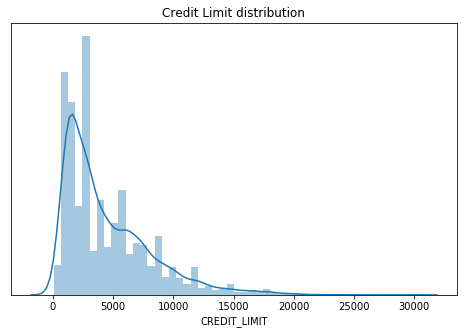

In [9]:
plt.figure(figsize=(8,5))
plt.title('Credit Limit distribution')
sns.distplot(cc_data['CREDIT_LIMIT'].dropna())
plt.yticks(ticks=[])

In [10]:
#We will impute the missing value with the most common entry in the similar behavior group
pd.value_counts(cc_data[((cc_data['BALANCE']>0) & (cc_data['BALANCE']<20)) & ((cc_data['MINIMUM_PAYMENTS']>10) &
                                                        (cc_data['MINIMUM_PAYMENTS']<18))]['CREDIT_LIMIT'])


1500.0    7
3000.0    5
1000.0    5
2000.0    2
5000.0    2
500.0     1
700.0     1
8000.0    1
4500.0    1
7500.0    1
4000.0    1
4800.0    1
Name: CREDIT_LIMIT, dtype: int64

In [11]:
cc_data['CREDIT_LIMIT'].fillna(1500,inplace=True)

    Now there is MINIMUM_PAYMENTS field with most number of null values. Ring any bells to address it?
---

    There's always the most common imputation techniques:
    1. Impute with mean, median, mode
    2. Remove the null valued rows altogether
    Since these are the most common methods, they are very simple and boring. If we are to use the aforementioned, we will only be looking at the field with missing values and impute the missing ones with some aggregate measure, but doesn't it mean we are biased only towards the field in question? So we take things up a notch with a better information gaining mechanism - KNNImputer.
    Based on the approach of KNN algorithm, it imputes the nulls by finding the similar neighbors. This is a better approach(obviously) because we take into consideration the other features as well.

In [12]:
knni = KNNImputer(n_neighbors=3)
cc_data_imputed = knni.fit_transform(cc_data[cc_data.columns.drop(['CUST_ID'])])


In [13]:
cc_data_imputed = pd.DataFrame(cc_data_imputed,columns=cc_data.columns.drop(['CUST_ID']))


In [14]:
cc_data_imputed.isna().sum()

BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64

     Essentially, we have done the same kind of imputing for both the columns. For CREDIT_LIMIT, we have created a simple formula that finds entries most similar to our target data-point and impute the mode from required group. For MINIMUM_PAYMENTS, since there are many nan's we used the KNNImputer to come up with a complex formula for imputation. 

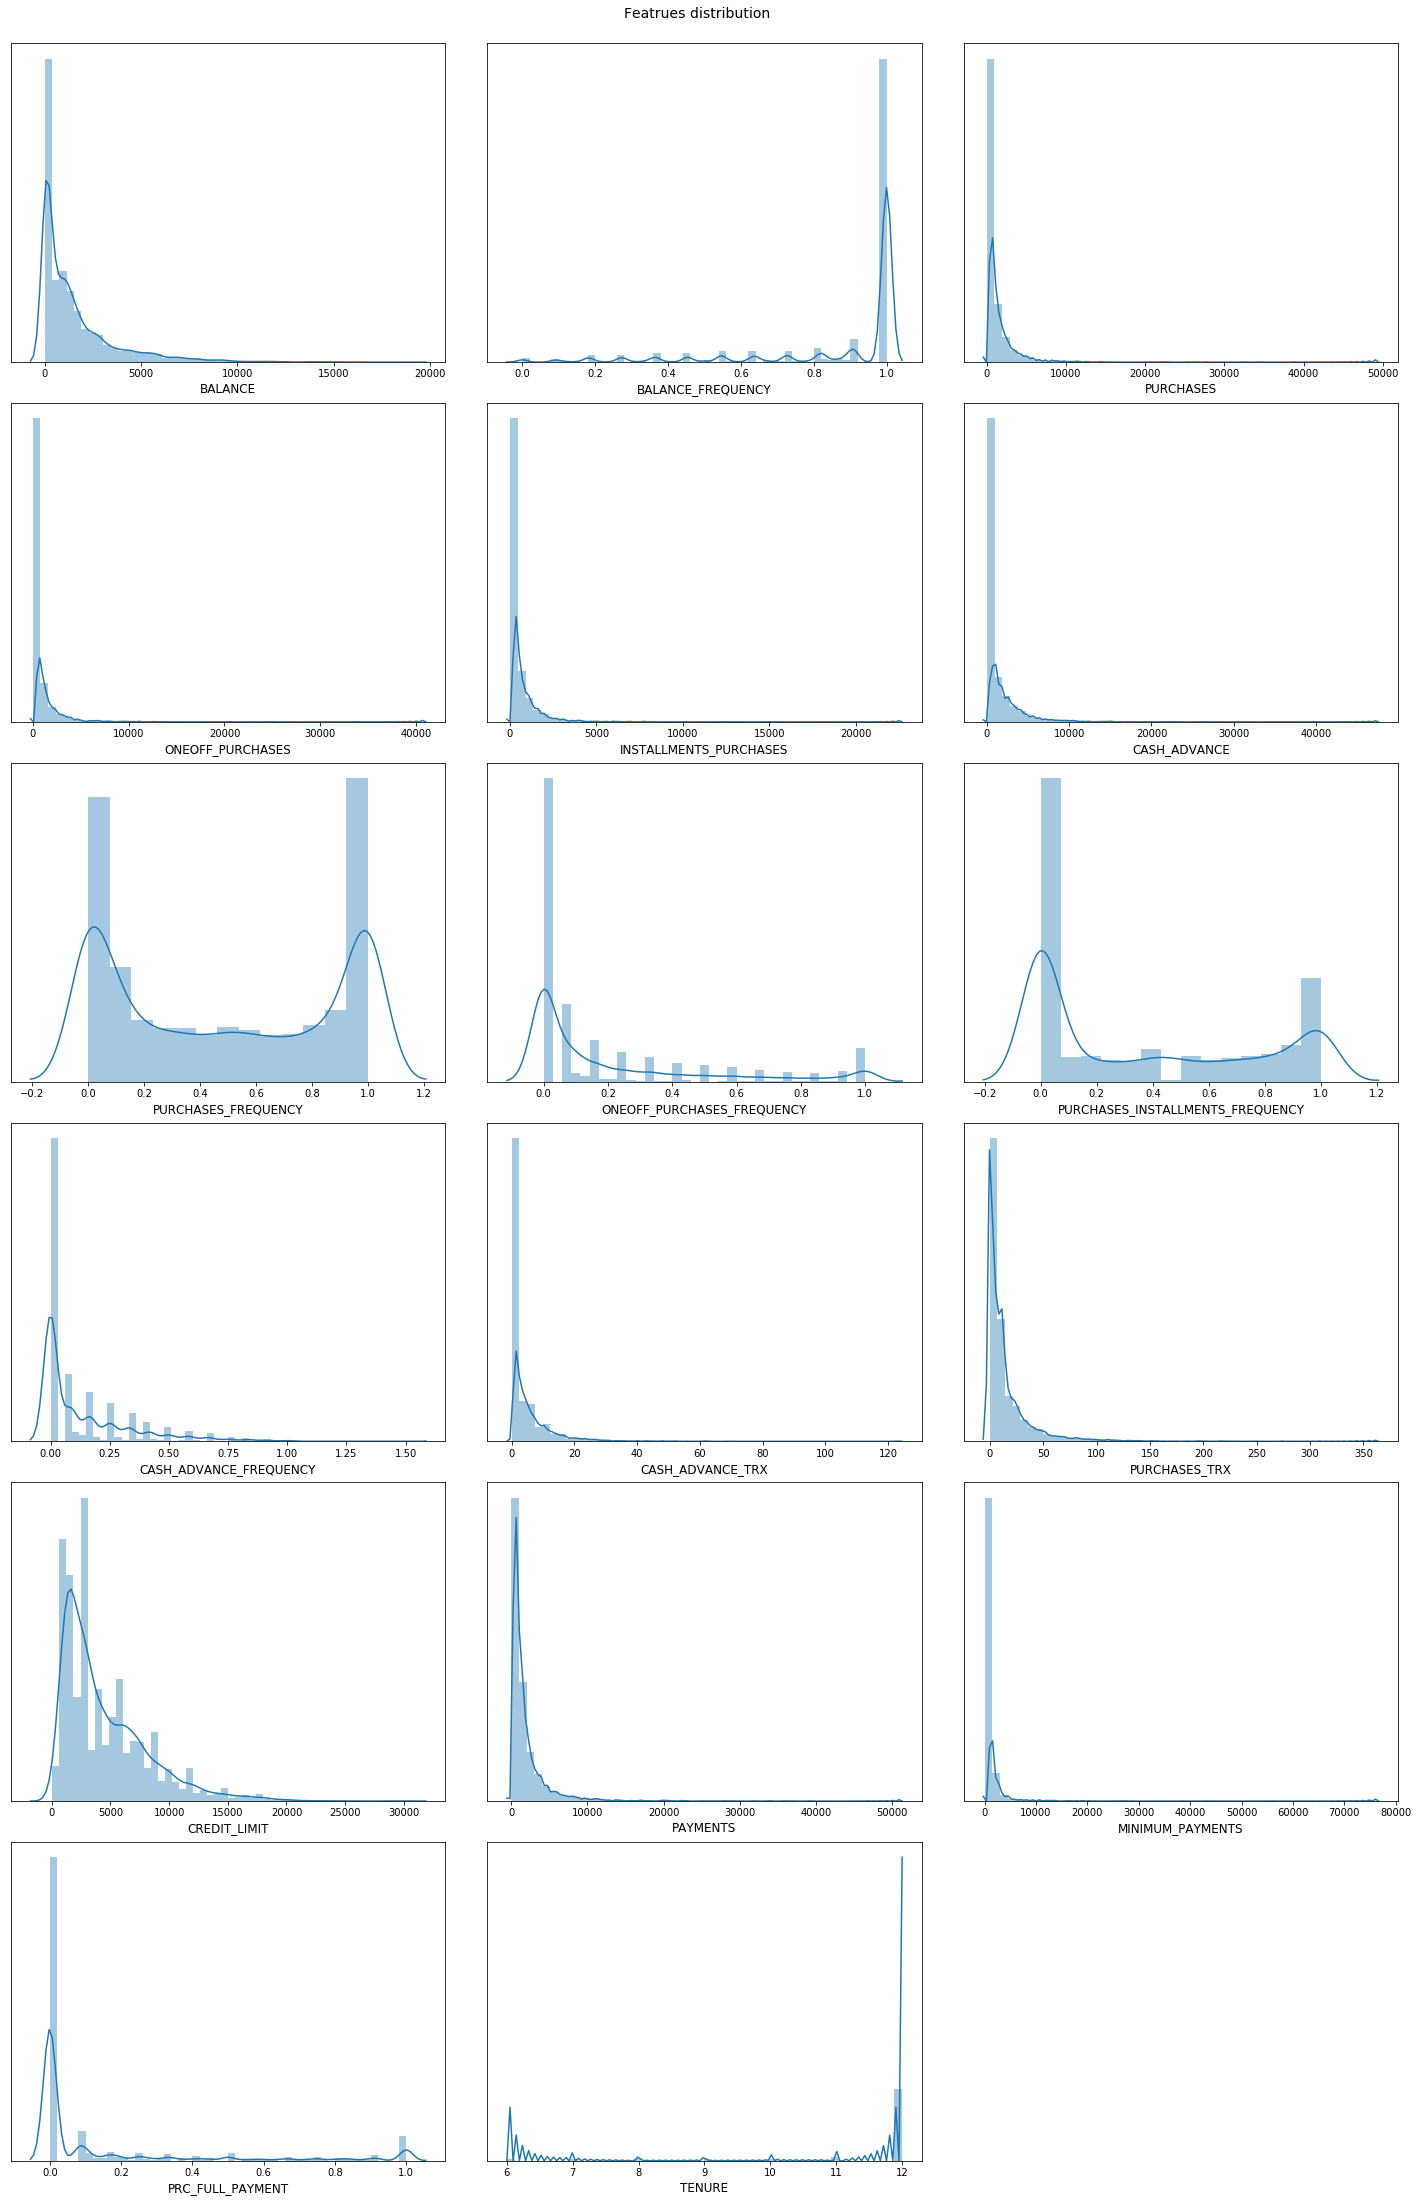

In [15]:
columns = cc_data_imputed.columns
fig,axs = plt.subplots(6,3,figsize=(20,30))
plt.suptitle('Featrues distribution',fontsize=14,y=1.01)
axs = axs.flatten()
axs[-1].axis('off')
plt.tight_layout(h_pad=2)
for ind,col in zip(range(len(columns)),columns):
    sns.distplot(cc_data_imputed[col],ax=axs[ind])
    axs[ind].set_yticks(ticks=[])
    axs[ind].set_xlabel(col,fontsize=12)

    Do you have a favorite from above distributions? I do... why don't you take a minute to think why a distribution could be favorite
---
  
    The distribution of puchases_frequency is sort of a personal favorite... it mimicks the real world scenario - the people who are skeptical about credit cards do not make any purchases, most of those that use credit cards use it extensively, the ones that maintain it steadily are very less and the distribution captures it perfectly. If it were up to me, I would be tempted to say this data is a clear representation of population looking only at purchases_frequency.


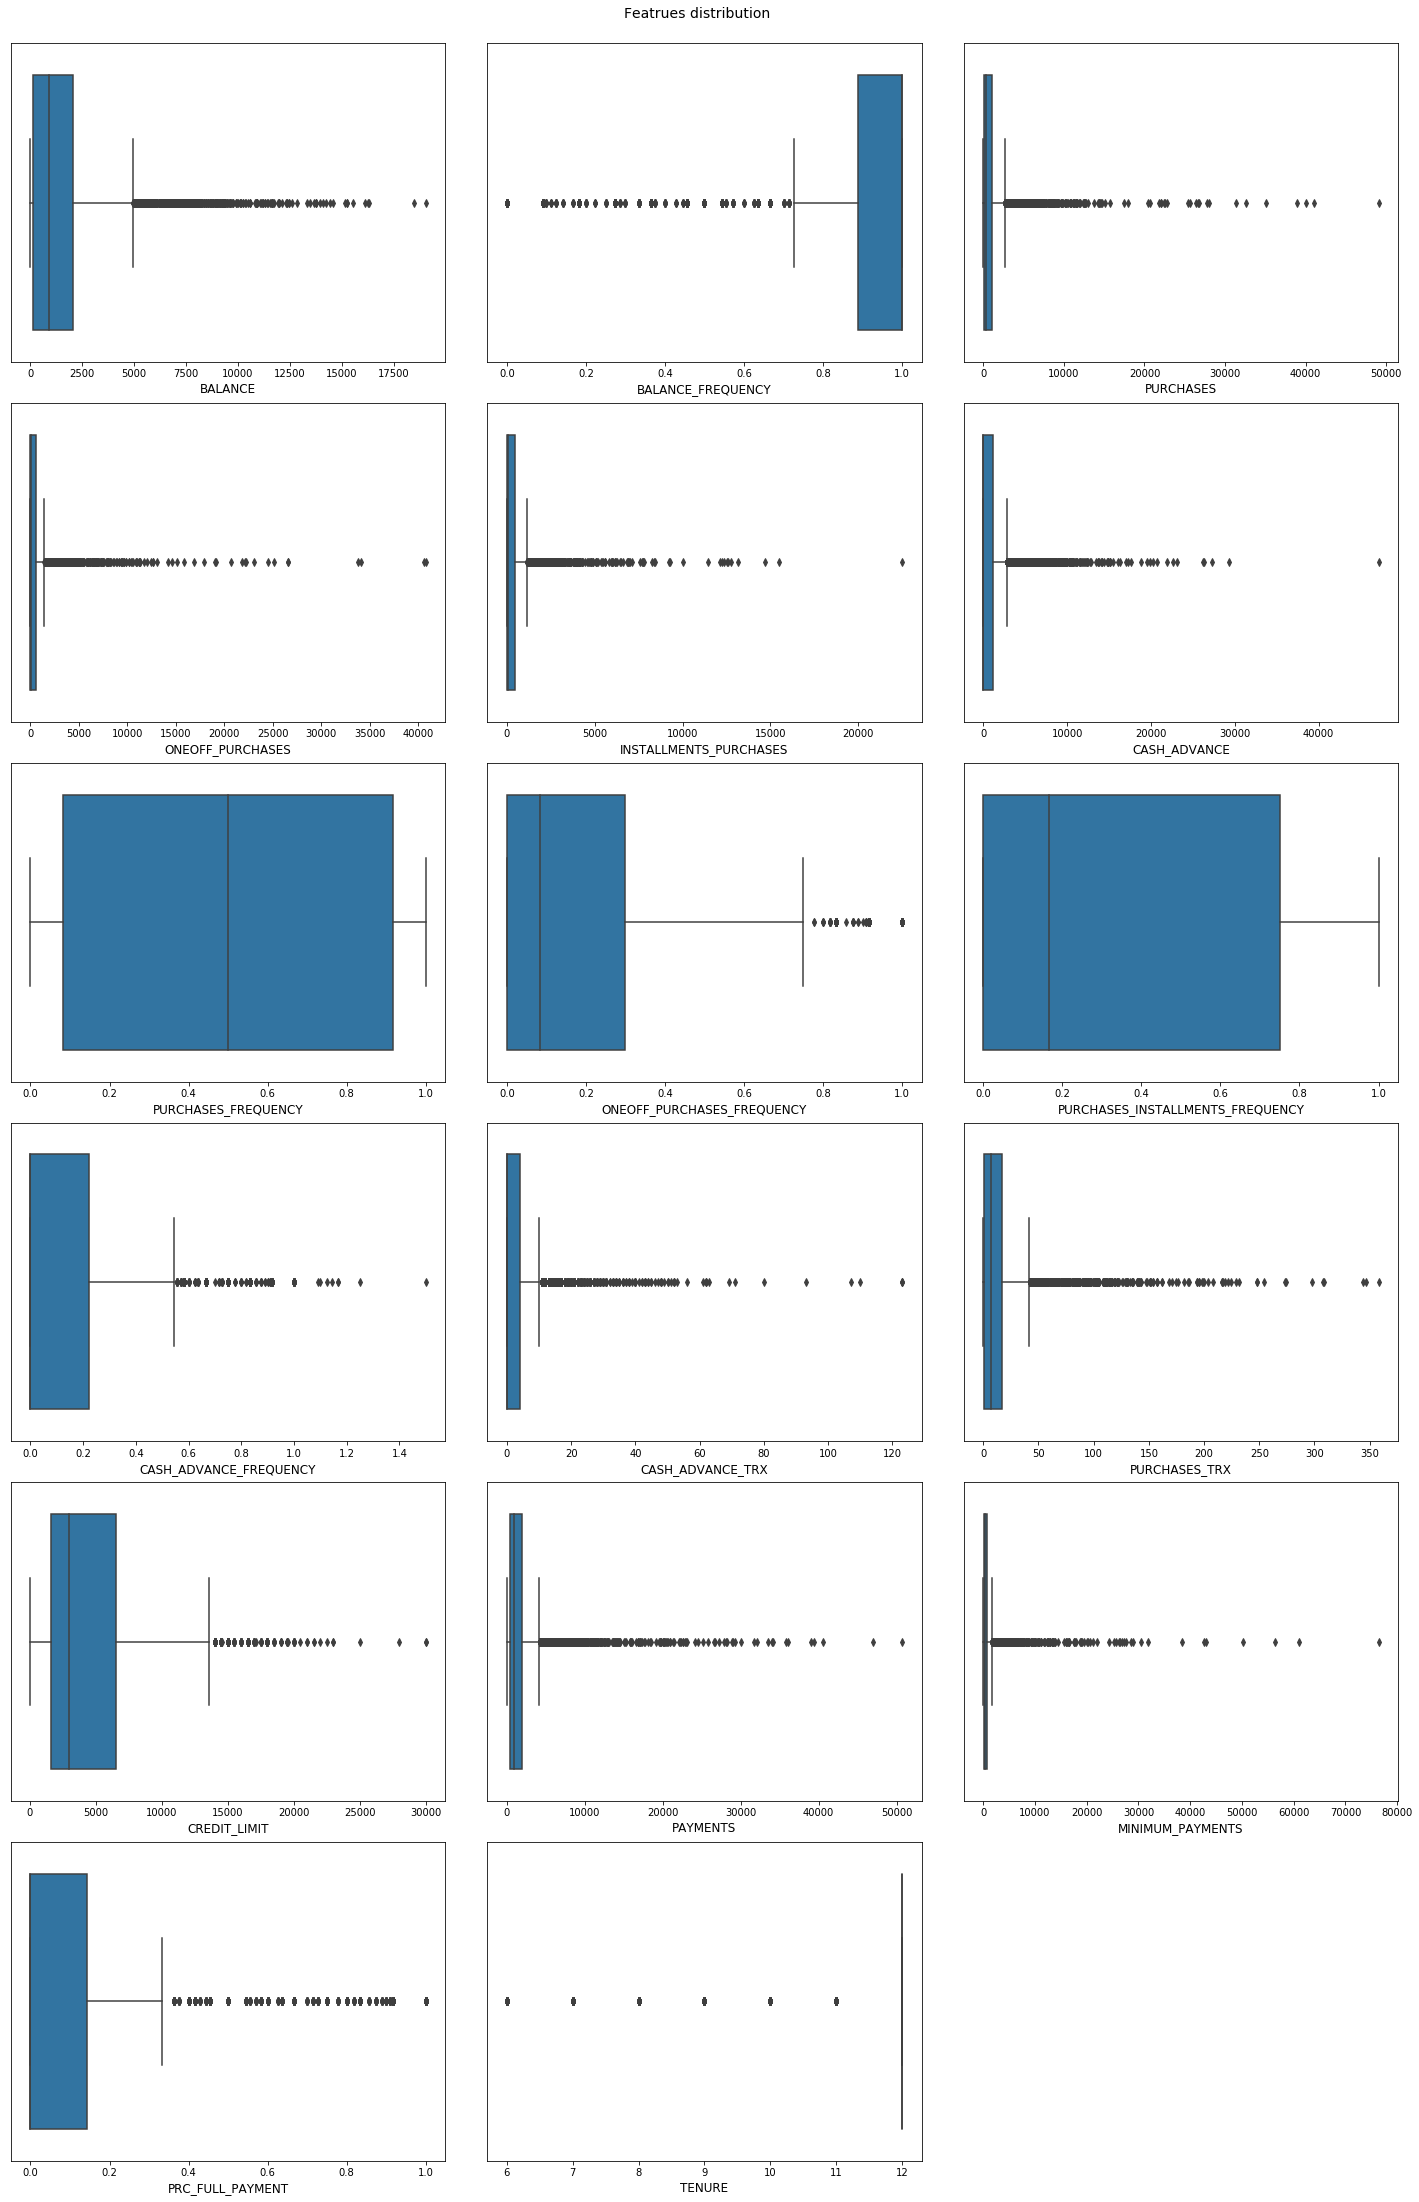

In [16]:
columns = cc_data_imputed.columns
fig,axs = plt.subplots(6,3,figsize=(20,30))
plt.suptitle('Featrues distribution',fontsize=14,y=1.01)
axs = axs.flatten()
axs[-1].axis('off')
plt.tight_layout(h_pad=2)
for ind,col in zip(range(len(columns)),columns):
    sns.boxplot(cc_data_imputed[col],ax=axs[ind])
    axs[ind].set_yticks(ticks=[])
    axs[ind].set_xlabel(col,fontsize=12)

In [17]:
cc_data_imputed[cc_data_imputed['CASH_ADVANCE_FREQUENCY']>1]['CASH_ADVANCE_FREQUENCY']


681     1.250000
1626    1.166667
2555    1.125000
2608    1.100000
3038    1.500000
3253    1.166667
8055    1.090909
8365    1.142857
Name: CASH_ADVANCE_FREQUENCY, dtype: float64

In [18]:
cc_data_imputed.loc[[681,1626,2555,2608,3038,3253,8055,8365],:]

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
681,5656.069801,1.000000,362.36,362.36,0.0,7240.433194,0.250000,0.250000,0.0,1.250000,12.0,2.0,8000.0,683.421497,2036.877611,0.0,8.0
1626,2876.009336,1.000000,152.61,152.61,0.0,3719.650168,0.333333,0.333333,0.0,1.166667,24.0,2.0,4000.0,248.342971,584.926336,0.0,6.0
2555,5906.184924,1.000000,141.80,141.80,0.0,1651.286918,0.125000,0.125000,0.0,1.125000,12.0,2.0,10000.0,933.969974,919.289675,0.0,8.0
2608,7801.511533,1.000000,231.40,231.40,0.0,4109.465221,0.100000,0.100000,0.0,1.100000,20.0,3.0,13500.0,1593.617739,1522.496755,0.0,10.0
3038,3846.742530,1.000000,0.00,0.00,0.0,1932.460679,0.000000,0.000000,0.0,1.500000,18.0,0.0,5600.0,496.245836,538.346874,0.0,6.0
3253,5709.486507,0.833333,0.00,0.00,0.0,2794.326341,0.000000,0.000000,0.0,1.166667,10.0,0.0,6000.0,550.513331,1299.463370,0.0,6.0
8055,1917.895730,1.000000,285.07,285.07,0.0,6084.858872,0.363636,0.363636,0.0,1.090909,28.0,6.0,3000.0,5692.682993,556.449635,0.0,11.0
8365,3857.562230,1.000000,0.00,0.00,0.0,2127.213754,0.000000,0.000000,0.0,1.142857,26.0,0.0,5000.0,617.508991,538.396872,0.0,7.0


    I hope you have your thinker hat on because... you guessed it! Don't you see anything odd or interesting from the box plots above? 
---

    CASH_ADVANCE_FREQUENCY, how is it above 1? CASH_ADVANCE_FREQUENCY is the number of times cash is paid in advance, as per the above rows the customers paid cash in advance more than 100 times for every 100 transactions and that is not logical. So, let's cap it back to 1

In [19]:
cc_data_imputed.loc[[681,1626,2555,2608,3038,3253,8055,8365],'CASH_ADVANCE_FREQUENCY'] = 1
cc_data_imputed.loc[[681,1626,2555,2608,3038,3253,8055,8365],:]

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
681,5656.069801,1.000000,362.36,362.36,0.0,7240.433194,0.250000,0.250000,0.0,1.0,12.0,2.0,8000.0,683.421497,2036.877611,0.0,8.0
1626,2876.009336,1.000000,152.61,152.61,0.0,3719.650168,0.333333,0.333333,0.0,1.0,24.0,2.0,4000.0,248.342971,584.926336,0.0,6.0
2555,5906.184924,1.000000,141.80,141.80,0.0,1651.286918,0.125000,0.125000,0.0,1.0,12.0,2.0,10000.0,933.969974,919.289675,0.0,8.0
2608,7801.511533,1.000000,231.40,231.40,0.0,4109.465221,0.100000,0.100000,0.0,1.0,20.0,3.0,13500.0,1593.617739,1522.496755,0.0,10.0
3038,3846.742530,1.000000,0.00,0.00,0.0,1932.460679,0.000000,0.000000,0.0,1.0,18.0,0.0,5600.0,496.245836,538.346874,0.0,6.0
3253,5709.486507,0.833333,0.00,0.00,0.0,2794.326341,0.000000,0.000000,0.0,1.0,10.0,0.0,6000.0,550.513331,1299.463370,0.0,6.0
8055,1917.895730,1.000000,285.07,285.07,0.0,6084.858872,0.363636,0.363636,0.0,1.0,28.0,6.0,3000.0,5692.682993,556.449635,0.0,11.0
8365,3857.562230,1.000000,0.00,0.00,0.0,2127.213754,0.000000,0.000000,0.0,1.0,26.0,0.0,5000.0,617.508991,538.396872,0.0,7.0


In [20]:
q3 = cc_data_imputed['BALANCE'].quantile(0.75)
q1 = cc_data_imputed['BALANCE'].quantile(0.25)
iqr = q3 - q1
outlier_start = q3+ (1.5 * iqr)
outlier_start


4942.9272155

    All values after 4942 can all be considered outliers based on the IQR rule. Let's invsitigate how other variables respond to these outliers

In [21]:
outlier_indices_balance = np.where(cc_data_imputed['BALANCE']>outlier_start)
cc_data_imputed.loc[outlier_indices_balance[0][:100],:]

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
15,6886.213231,1.0,1611.70,0.00,1611.70,2301.491267,0.500000,0.000000,0.500000,0.166667,4.0,11.0,8000.0,1993.439277,2109.906490,0.000000,12.0
21,6369.531318,1.0,6359.95,5910.04,449.91,229.028245,1.000000,0.916667,1.000000,0.333333,6.0,92.0,11250.0,2077.959051,1659.775075,0.000000,12.0
24,5368.571219,1.0,0.00,0.00,0.00,798.949863,0.000000,0.000000,0.000000,0.363636,4.0,0.0,6000.0,1422.726707,1657.002877,0.000000,11.0
28,7152.864372,1.0,387.05,204.55,182.50,2236.145259,0.666667,0.166667,0.416667,0.833333,16.0,8.0,10500.0,1601.448347,1648.851345,0.000000,12.0
30,12136.219960,1.0,3038.01,1013.20,2024.81,3183.583301,1.000000,0.166667,1.000000,0.500000,10.0,64.0,13000.0,4230.323491,3292.015030,0.000000,12.0
32,6732.823064,1.0,324.95,324.95,0.00,1189.533753,0.083333,0.083333,0.000000,0.166667,3.0,3.0,10500.0,1720.118876,2506.745366,0.000000,12.0
36,7427.076941,1.0,0.00,0.00,0.00,8873.375046,0.000000,0.000000,0.000000,0.727273,11.0,0.0,9000.0,1636.361601,1986.843608,0.000000,11.0
38,6269.418144,1.0,204.00,204.00,0.00,2925.699862,0.083333,0.083333,0.000000,0.333333,12.0,2.0,9000.0,1237.111661,2049.408839,0.000000,12.0
44,5315.945594,1.0,1525.44,469.80,1055.64,0.000000,1.000000,0.333333,1.000000,0.000000,0.0,20.0,8500.0,1430.341501,1318.714920,0.000000,12.0
59,5493.904060,1.0,229.00,0.00,229.00,970.591332,0.416667,0.000000,0.333333,0.333333,4.0,6.0,6000.0,2110.557023,1895.026170,0.000000,12.0


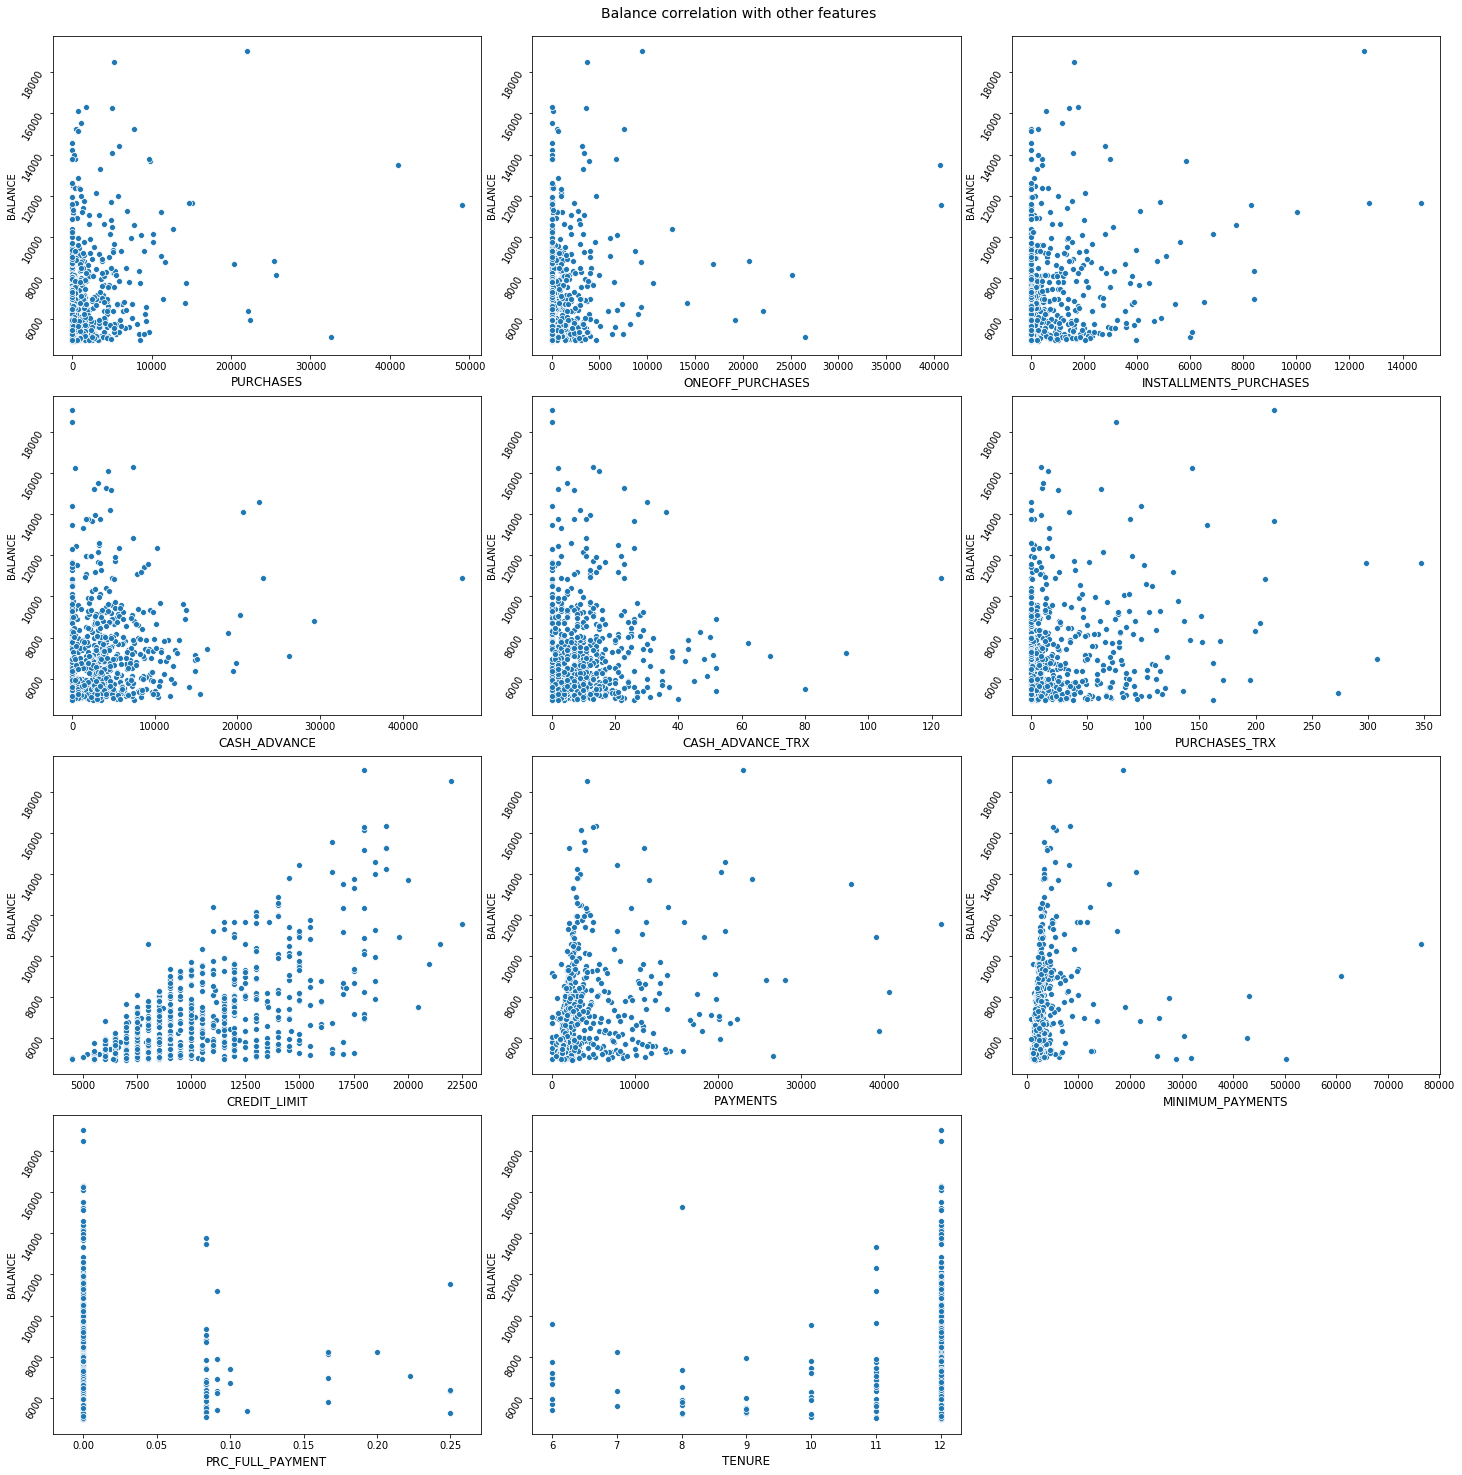

In [22]:
#none of the frequency features show any specific correlation, so let's look at the other features 
non_freq_cols = ['PURCHASES','ONEOFF_PURCHASES','INSTALLMENTS_PURCHASES','CASH_ADVANCE','CASH_ADVANCE_TRX',
                 'PURCHASES_TRX','CREDIT_LIMIT','PAYMENTS','MINIMUM_PAYMENTS','PRC_FULL_PAYMENT','TENURE']
fig,axs = plt.subplots(4,3,figsize=(20,20))
plt.suptitle('Balance correlation with other features',fontsize=14,y=1.01)
axs = axs.flatten()
axs[-1].axis('off')
plt.tight_layout(h_pad=2,w_pad=2)
for ind,col in zip(range(len(non_freq_cols)),non_freq_cols):
    sns.scatterplot(cc_data_imputed[col][outlier_indices_balance[0]],cc_data_imputed['BALANCE'][outlier_indices_balance[0]],ax=axs[ind])
    axs[ind].set_xlabel(col,fontsize=12)
    axs[ind].tick_params(axis='y',rotation=60)

    Credit_limit is the most correlated feature to Balance, understandably if balance is more credit card companies are inclined to offer more credit. Payments and minimum payments are slightly correlated since indirectly increased balance could lead to increased purchases and hence increased payments
    
    So, it is sort of understandable that these datapoints are not exactly outliers instead they are very influential. One way to deal with these is creating bins. Before we get to that let's see if the other columns have same number of outliers and if they do, is it at same indices?

In [23]:
outlier_count = {}
for col in cc_data_imputed.columns:    
    q3 = cc_data_imputed[col].quantile(0.75)
    q1 = cc_data_imputed[col].quantile(0.25)
    iqr = q3 - q1
    outlier_start = q3+ (1.5 * iqr)
    outlier_ind = np.where(cc_data_imputed[col]>outlier_start)[0]
    outlier_count[col] = len(outlier_ind)
    
outlier_count

{'BALANCE': 695,
 'BALANCE_FREQUENCY': 0,
 'PURCHASES': 808,
 'ONEOFF_PURCHASES': 1013,
 'INSTALLMENTS_PURCHASES': 867,
 'CASH_ADVANCE': 1030,
 'PURCHASES_FREQUENCY': 0,
 'ONEOFF_PURCHASES_FREQUENCY': 782,
 'PURCHASES_INSTALLMENTS_FREQUENCY': 0,
 'CASH_ADVANCE_FREQUENCY': 525,
 'CASH_ADVANCE_TRX': 804,
 'PURCHASES_TRX': 766,
 'CREDIT_LIMIT': 248,
 'PAYMENTS': 808,
 'MINIMUM_PAYMENTS': 891,
 'PRC_FULL_PAYMENT': 1474,
 'TENURE': 0}

    All variables with outliers have somewhere between 2-10% of outliers. Looks like most of those are legit datapoints, so let's increase the range: outliers will now be > or < 3*iqr from lower and upper boundaries respectively. 

    But wait! is that it? are you sure we can directly intrepret it's better to increase the range?
---

    Let's try transforming the data first. We have noticed earlier itself that our data is skewed, so log_transformation seems like a good idea.

In [24]:
#All columns could use log_transformation
cc_data_imputed_log = cc_data_imputed.apply(lambda val: np.log(val+0.001))
cc_data_imputed_log.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,3.711173,-0.199449,4.558089,-6.907755,4.558089,-6.907755,-1.785775,-6.907755,-2.472982,-6.907755,-6.907755,0.693647,6.907756,5.307292,4.938142,-6.907755,2.48499
1,8.071677,-0.094211,-6.907755,-6.907755,-6.907755,8.770741,-6.907755,-6.907755,-6.907755,-1.382302,1.386544,-6.907755,8.853666,8.319482,6.977600,-1.499588,2.48499
2,7.822104,0.001000,6.650500,6.650500,-6.907755,-6.907755,0.001000,0.001000,-6.907755,-6.907755,-6.907755,2.484990,8.922658,6.433049,6.441402,-6.907755,2.48499
3,7.418584,-0.450414,7.312554,7.312554,-6.907755,5.326851,-2.472982,-2.472982,-6.907755,-2.472982,0.001000,0.001000,8.922658,-6.907755,6.105262,-6.907755,2.48499
4,6.706514,0.001000,2.772651,2.772651,-6.907755,-6.907755,-2.472982,-2.472982,-6.907755,-6.907755,-6.907755,0.001000,7.090078,6.519642,5.500410,-6.907755,2.48499


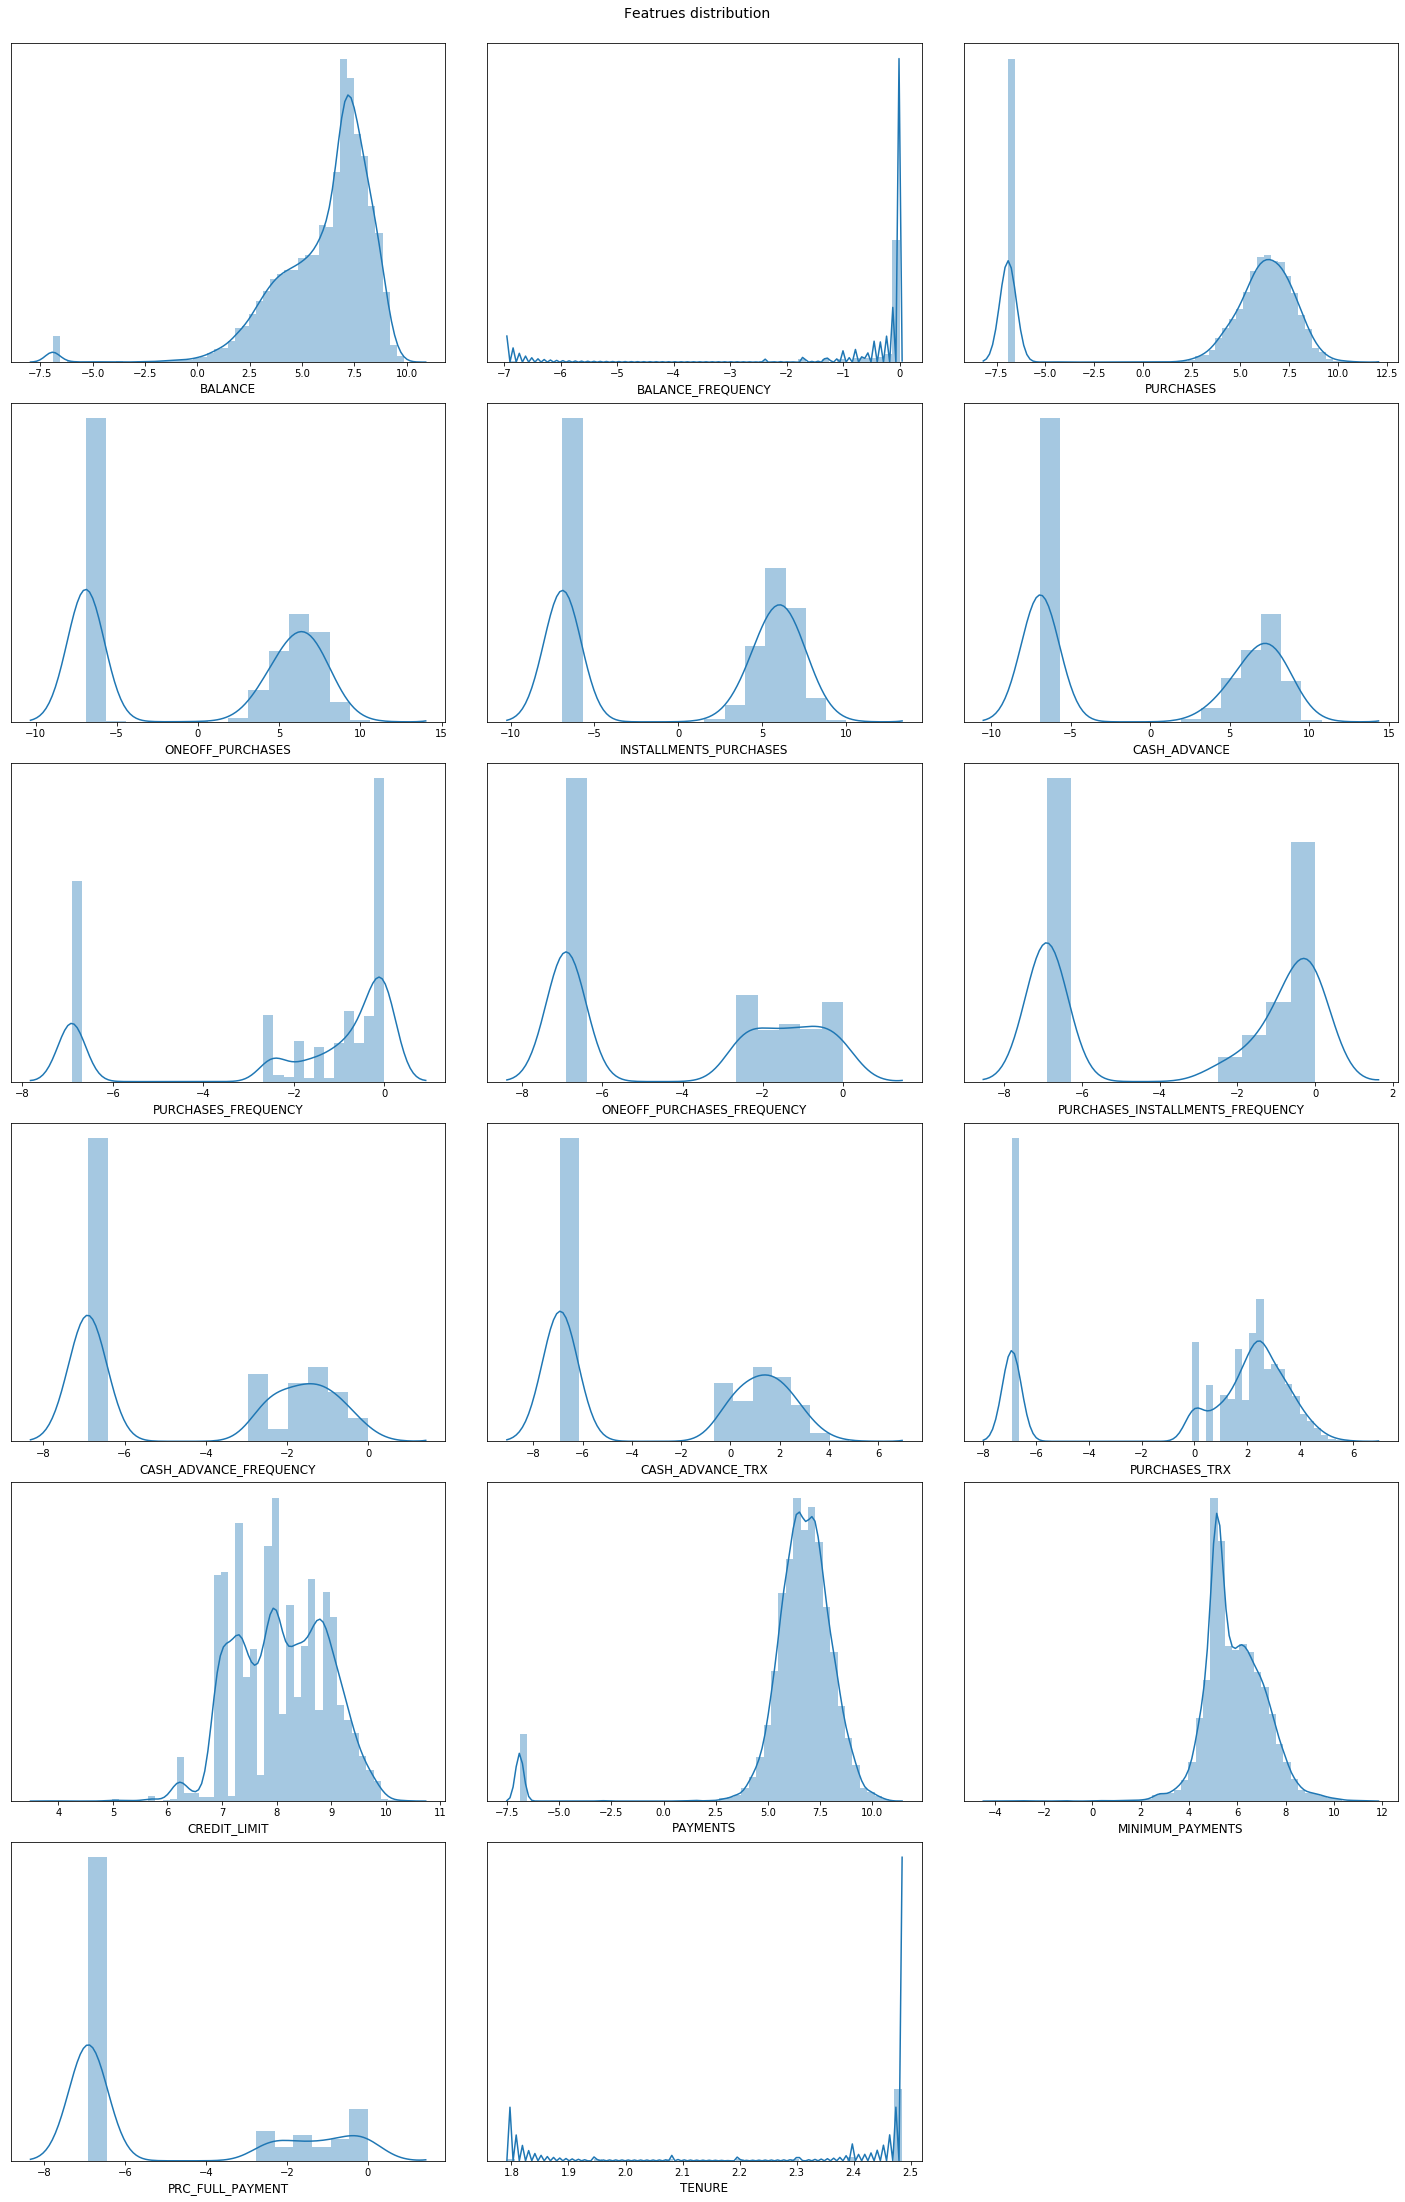

In [25]:
fig,axs = plt.subplots(6,3,figsize=(20,30))
plt.suptitle('Featrues distribution',fontsize=14,y=1.01)
axs = axs.flatten()
axs[-1].axis('off')
plt.tight_layout(h_pad=2)
for ind,col in zip(range(len(columns)),columns):
    sns.distplot(cc_data_imputed_log[col],ax=axs[ind])
    axs[ind].set_yticks(ticks=[])
    axs[ind].set_xlabel(col,fontsize=12)

In [26]:
outlier_count = {}
for col in cc_data_imputed.columns:    
    q3 = cc_data_imputed[col].quantile(0.75)
    q1 = cc_data_imputed[col].quantile(0.25)
    iqr = q3 - q1
    outlier_start = q3+ (3 * iqr)
    outlier_ind = np.where(cc_data_imputed[col]>outlier_start)[0]
    outlier_count[col] = [len(outlier_ind),outlier_ind]
    
for key in outlier_count.keys():
    print(key,':',outlier_count[key][0])

BALANCE : 194
BALANCE_FREQUENCY : 0
PURCHASES : 391
ONEOFF_PURCHASES : 566
INSTALLMENTS_PURCHASES : 395
CASH_ADVANCE : 486
PURCHASES_FREQUENCY : 0
ONEOFF_PURCHASES_FREQUENCY : 0
PURCHASES_INSTALLMENTS_FREQUENCY : 0
CASH_ADVANCE_FREQUENCY : 67
CASH_ADVANCE_TRX : 368
PURCHASES_TRX : 356
CREDIT_LIMIT : 10
PAYMENTS : 402
MINIMUM_PAYMENTS : 462
PRC_FULL_PAYMENT : 1081
TENURE : 0


    That's pretty decent, this reduced the outlier count considerably. Great! Now comes the twist, the approach we followed for outlier detection is not the right choice. Data is skewed and if we are calculating outlier based on 1.5 or 3 * iqr chances are information is not captured properly. Consider this, if we have a normal distribution i.e, the data is symmetric about a point, identifying the points that are furthest from most dense regions can clearly be done by applying a threshold.
    Since we don't have a symmetic distribution even after transformation, it's safe to say we will have to use non-parametric methods
    
#### And hey! I believe when it comes to credit cards and finances, most often than not there are no outliers just some people that are very different from a country's economic outlook. Don't just take my word for it instead search for facts to back your belief: be it agreeing with me or not

In [27]:
#Isolation Forest
pred = IsolationForest().fit_predict(cc_data_imputed['BALANCE'].values.reshape(-1,1))

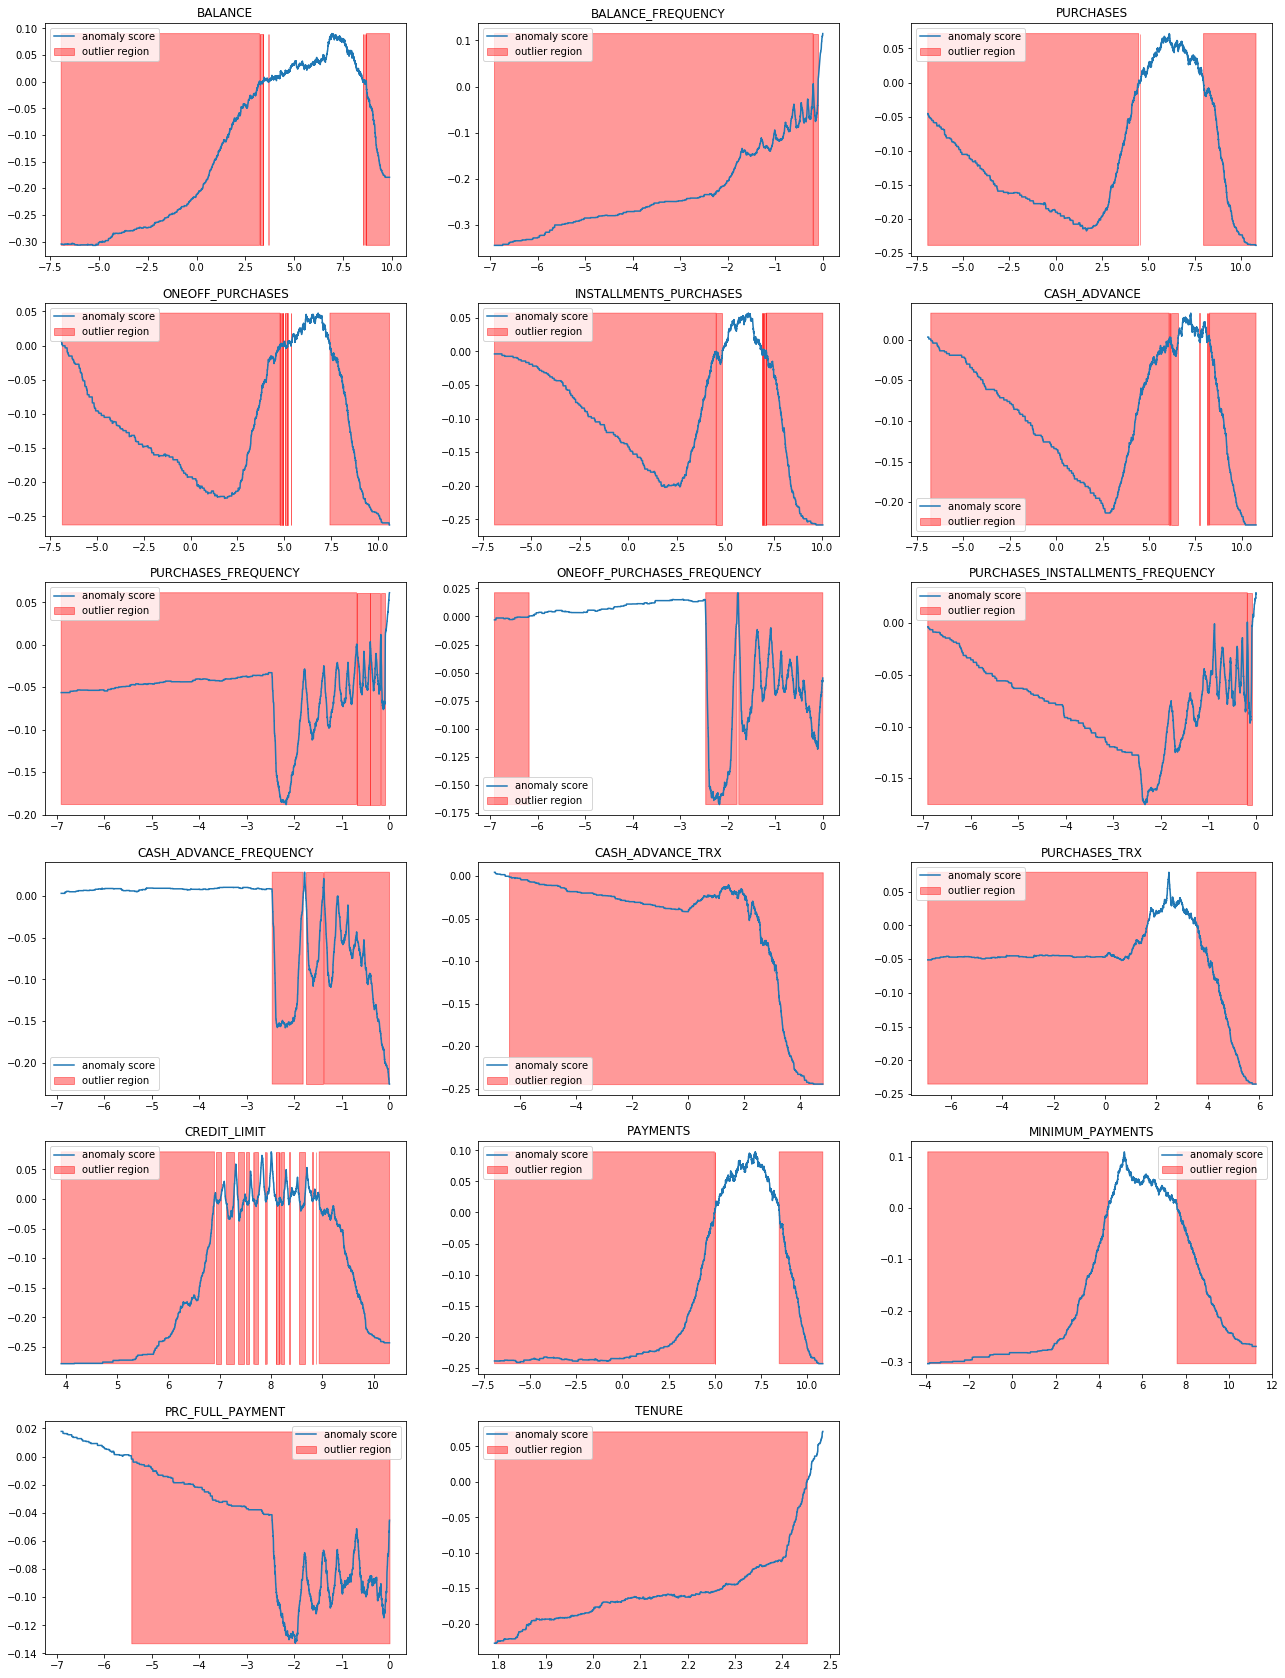

In [28]:
fig, axs = plt.subplots(6, 3, figsize=(22, 30), facecolor='w', edgecolor='k')
axs = axs.ravel()
axs[-1].axis('off')
dict_ind = {}
for i, column in enumerate(columns):
    isolation_forest = IsolationForest(contamination='auto')
    outlier = isolation_forest.fit(cc_data_imputed_log[column].values.reshape(-1,1))

    xx = np.linspace(cc_data_imputed_log[column].min(), cc_data_imputed_log[column].max(), len(cc_data_imputed_log)).reshape(-1,1)
    anomaly_score = isolation_forest.decision_function(xx)
    outlier = isolation_forest.predict(xx)
    dict_ind[column] = outlier
    
    axs[i].plot(xx, anomaly_score, label='anomaly score')
    axs[i].fill_between(xx.T[0], np.min(anomaly_score), np.max(anomaly_score), 
                     where=outlier==-1, color='r', 
                     alpha=.4, label='outlier region')
    axs[i].legend()
    axs[i].set_title(column)
    

    Okay, this behavior is worse than expected. Instead of going 1 step forward, we came 2 steps back. However, the takeaway here is: real world data doesn't always budge to pre-defined methods, that doesn't mean the methods are not effective, it's just that they aren't a perfect fit in some situations.
    
    However, we can also try methods like squareroot, cuberoot, log(log())... this is where domain expertise and data understanding comes into play. The methods we've used weren't of much use, with domain expertise we can comeup with conditions to define outlier boundaries, since that's not an option here we go with data understanding.
    
    When we looked for outliers in a table above, we noticed that many of them kind of make sense. We can either create elaborate formulas like if balance > x and credit_limit < y and payments > z, then outlier but this might work only for the observations we have noticed. It's not practical to go through each and every observation and come to a conclusion. So, a more robust and workable idea would be our initial notion of binning data
    
*Note: The above graph has been extracted from kaggle for demonstration*

### EDA

    Before binning the data it's important to understand how variables interact with each other, but why?

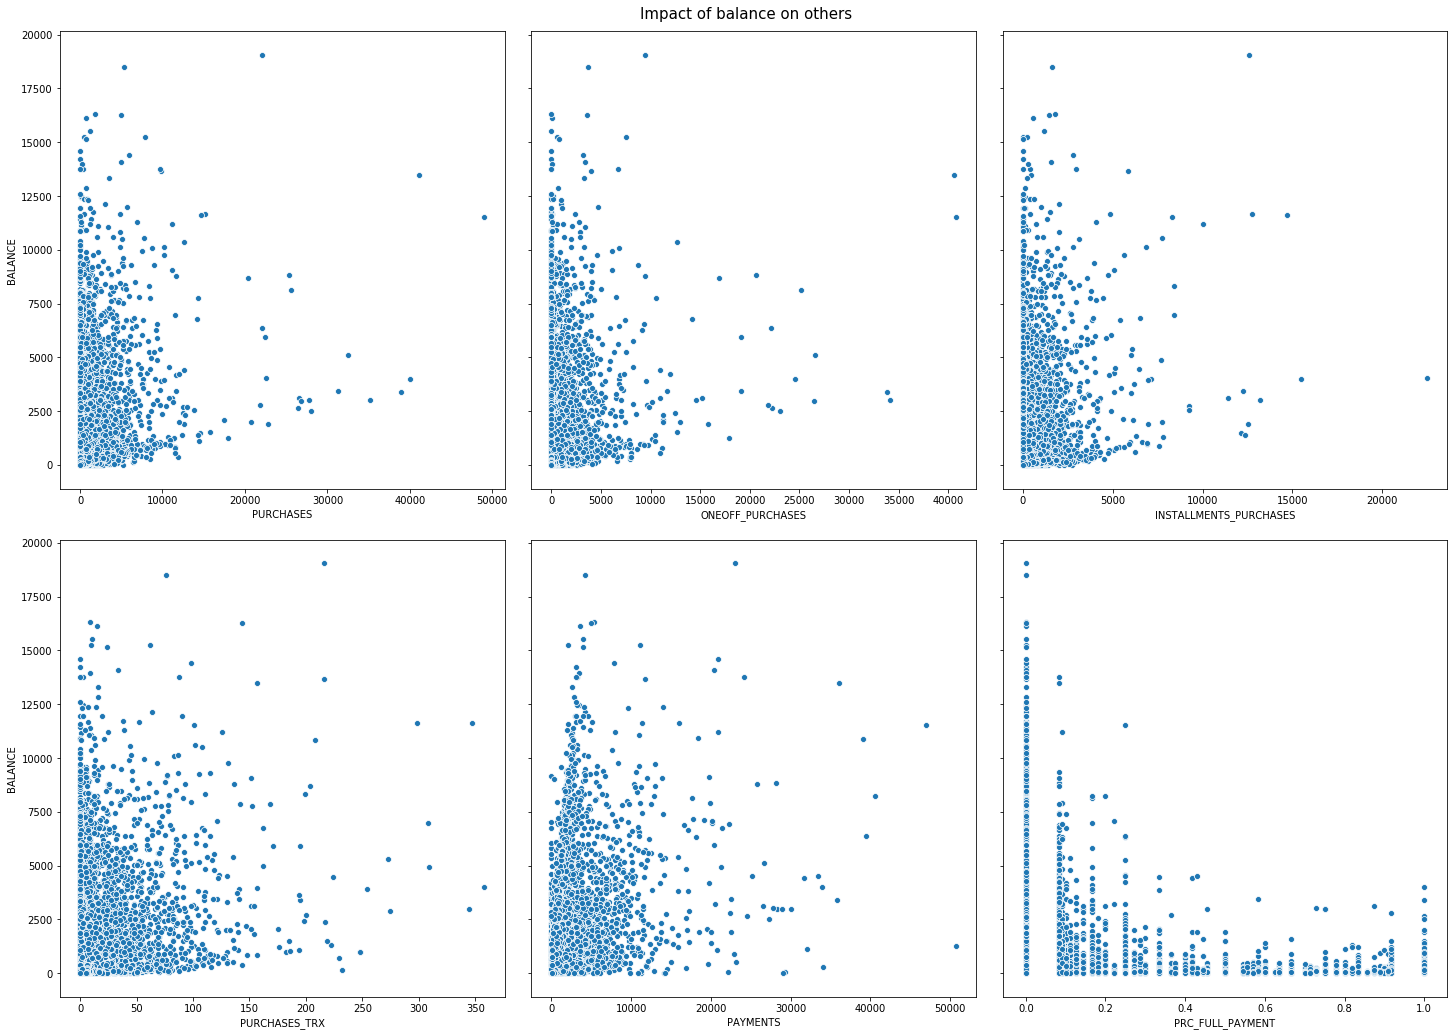

In [29]:
fig, axs = plt.subplots(2,3,figsize=(20,14),sharey=True)
axs = axs.flatten()
plt.tight_layout(h_pad=3)
plt.suptitle('Impact of balance on others',y=1.01,fontsize=15)
for ind,col in zip(range(6),['PURCHASES','ONEOFF_PURCHASES','INSTALLMENTS_PURCHASES','PURCHASES_TRX','PAYMENTS','PRC_FULL_PAYMENT']):
    sns.scatterplot(cc_data_imputed[col],cc_data_imputed['BALANCE'],ax = axs[ind])


    There are some interesting findings:
    1. Most of the variables do not have an ideal scenario i.e, proportional to balance
    2. PRC_FULL_PAYMENT is showing inverse relation, customers are expected to make full payment when they have more balance but here as balance increases the full payment percentage decreases
    3. Balance and payments do not see eye to eye, there is no vivid pattern for payments. But we should say, the credit card company is doing a decent job in collecting the dues and that can be noticed with overlap in purchases & payments from 2 different graphs ofcourse
    4. Installments_purchases checks out, it reduces with increased account balance. No one likes to be in debt
    
    Other interesting combinations to look at:
    purchases vs prc_full_payment, payments, oneoff_purchases

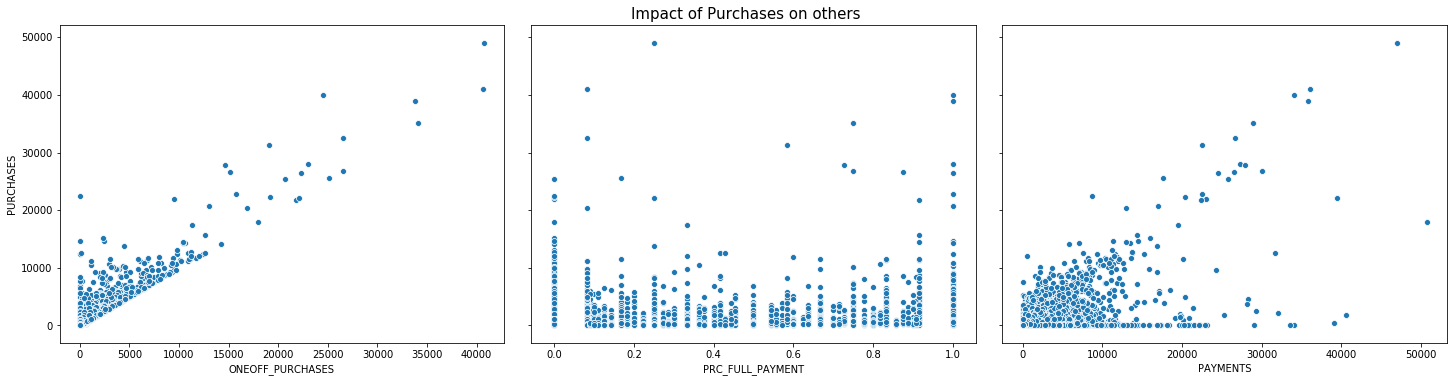

In [30]:
fig, axs = plt.subplots(1,3,figsize=(20,5),sharey=True)
axs = axs.flatten()
plt.tight_layout(h_pad=3)
plt.suptitle('Impact of Purchases on others',y=1.01,fontsize=15)
for ind,col in zip(range(6),['ONEOFF_PURCHASES','PRC_FULL_PAYMENT','PAYMENTS']):
    sns.scatterplot(cc_data_imputed[col],cc_data_imputed['PURCHASES'],ax = axs[ind])


    The common assumption: with increase in purchase value, chances for installments_payments increases
    Only problem with it is that the high income group is often excluded. Now from our graph puchases vs oneoff_purchases, increased value in purchases has increased chances of oneoff_purchases at the same time the density of population in that area also reduced drastically. So, it is safe to say that chances for these people belonging to high income groups is high.
    
    Supporting our previous statement, the prc_full_payment is almost uniformly distributed because there are always people who would prefer paying over a period rather than single time and hence the distribution says pretty much the same.

Text(0, 0.5, 'VALUE')

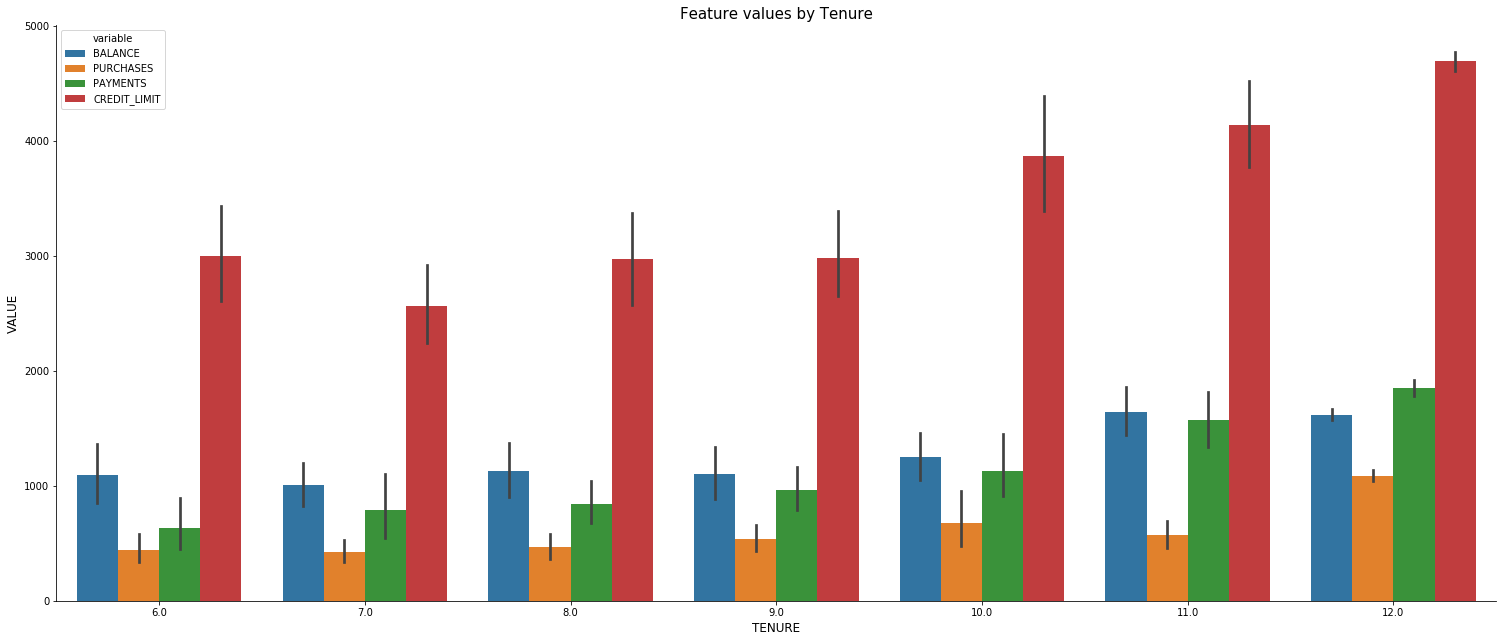

In [31]:
fig = plt.figure(figsize=(20,8))
ax = fig.add_axes((0,0,1,1))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.title('Feature values by Tenure',fontsize = 15)
#cc_data_imputed['tenure_str'] = cc_data_imputed['TENURE'].apply(lambda val: str(val))
sns.barplot(x='TENURE', y='value', hue='variable',
            data=cc_data_imputed[['BALANCE','PURCHASES','PAYMENTS','CREDIT_LIMIT','TENURE']].melt(id_vars='TENURE', var_name='variable'),
           ax=ax,)
ax.set_xlabel('TENURE',fontsize=12)
ax.set_ylabel('VALUE',fontsize=12)





    There are not many people with tenure less than 12. However, we can clearly note that the people with all tenures have almost same amounts of credit limit. That might not be good, right? can you think why?
---
    
    1. When a credit card company offers credit in a card that amount is locked to the particular customer irrespective of usage. So, initially if we can reduce the limit for new customers, we can allocate more for the ones with higher tenure
    2. Most of the new customers are hesitant to use credit cards to the fullest from the begining, rendering the locked amount unused
    
    From the graph:
    1. We can see that from the begining balance is higher than purchases and payments, with time this gap reduces and older customers tend to have comparitively very high utilization. So, concentration on customer retention is more important than the initial spendings

(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5, 16.5]),
 <a list of 17 Text xticklabel objects>)

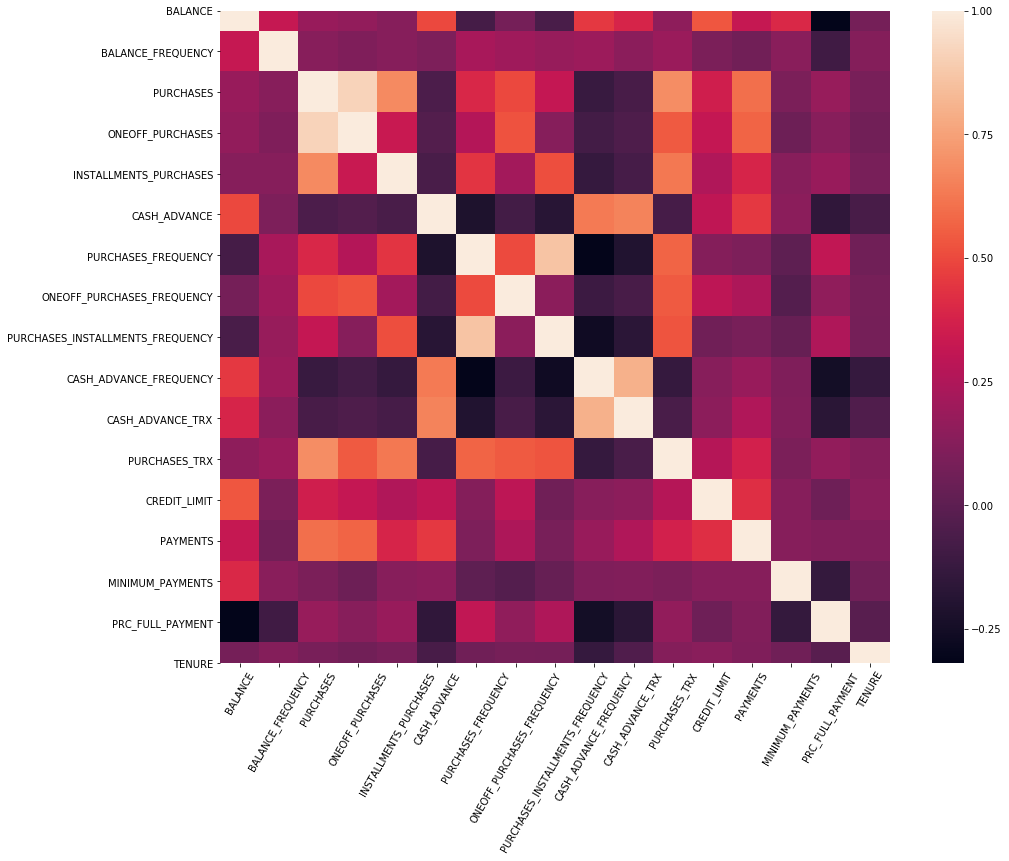

In [32]:
plt.figure(figsize=(15,12))
sns.heatmap(cc_data_imputed.corr())
plt.xticks(rotation=60)

    What can you do when there is no or very less correlation amongst the variables? This one's for the road... it's up to you figure out what to do.

Text(0.5, 0, 'Frequency')

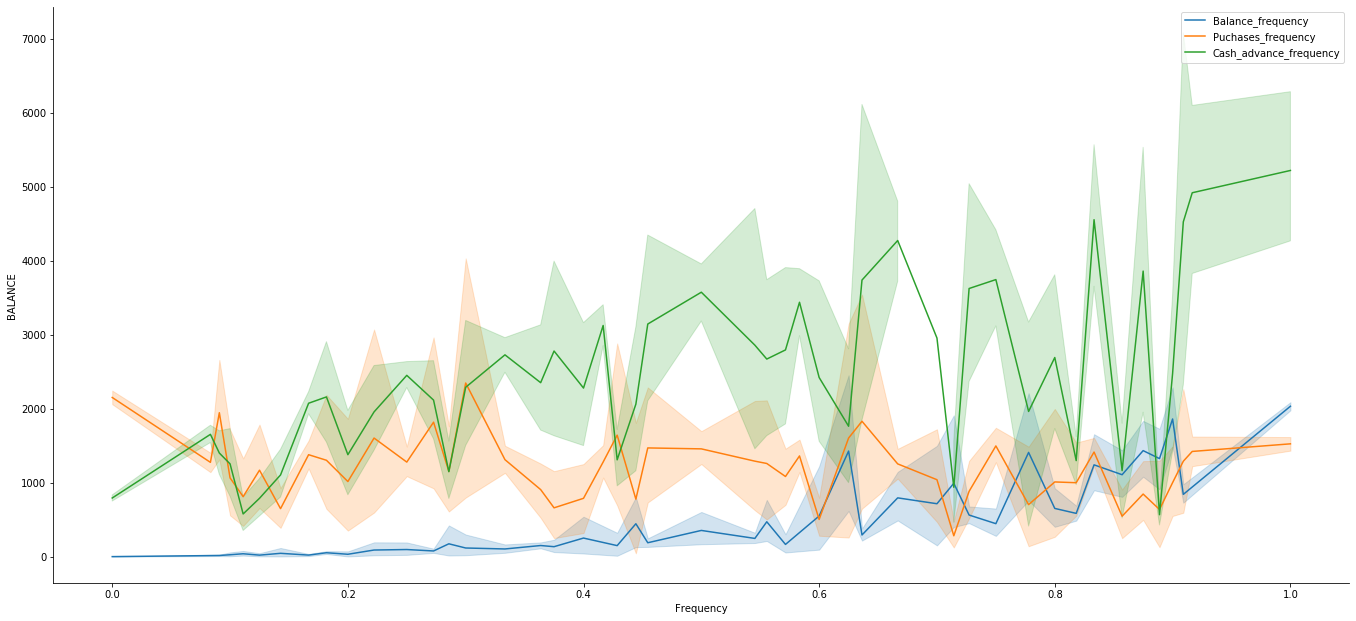

In [35]:
fig = plt.figure(figsize=(18,8))
ax = fig.add_axes((0,0,1,1))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
sns.lineplot('BALANCE_FREQUENCY','BALANCE',data=cc_data_imputed,ax=ax,label='Balance_frequency')
sns.lineplot('PURCHASES_FREQUENCY','BALANCE',data=cc_data_imputed,ax=ax,label='Puchases_frequency')
sns.lineplot('CASH_ADVANCE_FREQUENCY','BALANCE',data=cc_data_imputed,ax=ax,label='Cash_advance_frequency')
ax.set_xlabel('Frequency')

    The clumsy graph above is a simple line graph for 3 variables. The shading around the line represents high density of population in that region.
    
    - You would expect that with increased balance, there would be an increase in purchasing. But, the orange line states something else: purchasing increased irrespective of balance
    - As balance increases the fluctuations in cash_advance also increase. This has a good insight: one wouldn't like to stay in debt when there's good amount of balance


In [37]:
#Let's bin the data

norm_cols = ['BALANCE','PURCHASES','ONEOFF_PURCHASES','INSTALLMENTS_PURCHASES','CASH_ADVANCE','CREDIT_LIMIT',
             'PAYMENTS','MINIMUM_PAYMENTS',]

freq_cols = ['BALANCE_FREQUENCY','PURCHASES_FREQUENCY','ONEOFF_PURCHASES_FREQUENCY','PURCHASES_INSTALLMENTS_FREQUENCY',
'CASH_ADVANCE_FREQUENCY','PRC_FULL_PAYMENT']

#'CASH_ADVANCE_TRX','PURCHASES_TRX','TENURE' do not need any binning


In [38]:
cc_data_binned = pd.DataFrame()
for col in norm_cols:
    bins = pd.IntervalIndex.from_tuples(closed = 'left',data = [(0, 200), (200, 700), (700, 2500),(2500,5000),(5000,10000),(10000,100000000)])
    cc_data_binned[col] = pd.cut(cc_data_imputed[col], bins,include_lowest=True)
    
for col in freq_cols:
    bins = pd.IntervalIndex.from_tuples(closed = 'left',data = [(0, 0.1), (0.1,0.3), (0.3,0.6),(0.6,0.8),(0.8,2)])
    cc_data_binned[col] = pd.cut(cc_data_imputed[col],bins,include_lowest=True)
    
cc_data_binned['CREDIT_LIMIT'] = pd.cut(cc_data_imputed['CREDIT_LIMIT'],pd.IntervalIndex.from_tuples(closed = 'left',data = [(0, 2000), (2000, 5000), (5000, 8000),(8000,13000),(13000,20000),(20000,10000000)]),include_lowest=True)

cc_data_binned[['CASH_ADVANCE_TRX','PURCHASES_TRX','TENURE']] = cc_data_imputed[['CASH_ADVANCE_TRX','PURCHASES_TRX','TENURE']]

In [39]:
cc_data_binned.head()

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,BALANCE_FREQUENCY,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,PRC_FULL_PAYMENT,CASH_ADVANCE_TRX,PURCHASES_TRX,TENURE
0,"[0, 200)","[0, 200)","[0, 200)","[0, 200)","[0, 200)","[0, 2000)","[200, 700)","[0, 200)","[0.8, 2.0)","[0.1, 0.3)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)",0.0,2.0,12.0
1,"[2500, 5000)","[0, 200)","[0, 200)","[0, 200)","[5000, 10000)","[5000, 8000)","[2500, 5000)","[700, 2500)","[0.8, 2.0)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)","[0.1, 0.3)","[0.1, 0.3)",4.0,0.0,12.0
2,"[700, 2500)","[700, 2500)","[700, 2500)","[0, 200)","[0, 200)","[5000, 8000)","[200, 700)","[200, 700)","[0.8, 2.0)","[0.8, 2.0)","[0.8, 2.0)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)",0.0,12.0,12.0
3,"[700, 2500)","[700, 2500)","[700, 2500)","[0, 200)","[200, 700)","[5000, 8000)","[0, 200)","[200, 700)","[0.6, 0.8)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)",1.0,1.0,12.0
4,"[700, 2500)","[0, 200)","[0, 200)","[0, 200)","[0, 200)","[0, 2000)","[200, 700)","[200, 700)","[0.8, 2.0)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)","[0.0, 0.1)",0.0,1.0,12.0


In [40]:
cc_data_binned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 17 columns):
BALANCE                             8950 non-null category
PURCHASES                           8950 non-null category
ONEOFF_PURCHASES                    8950 non-null category
INSTALLMENTS_PURCHASES              8950 non-null category
CASH_ADVANCE                        8950 non-null category
CREDIT_LIMIT                        8950 non-null category
PAYMENTS                            8950 non-null category
MINIMUM_PAYMENTS                    8950 non-null category
BALANCE_FREQUENCY                   8950 non-null category
PURCHASES_FREQUENCY                 8950 non-null category
ONEOFF_PURCHASES_FREQUENCY          8950 non-null category
PURCHASES_INSTALLMENTS_FREQUENCY    8950 non-null category
CASH_ADVANCE_FREQUENCY              8950 non-null category
PRC_FULL_PAYMENT                    8950 non-null category
CASH_ADVANCE_TRX                    8950 non-null float64
PURCHASES

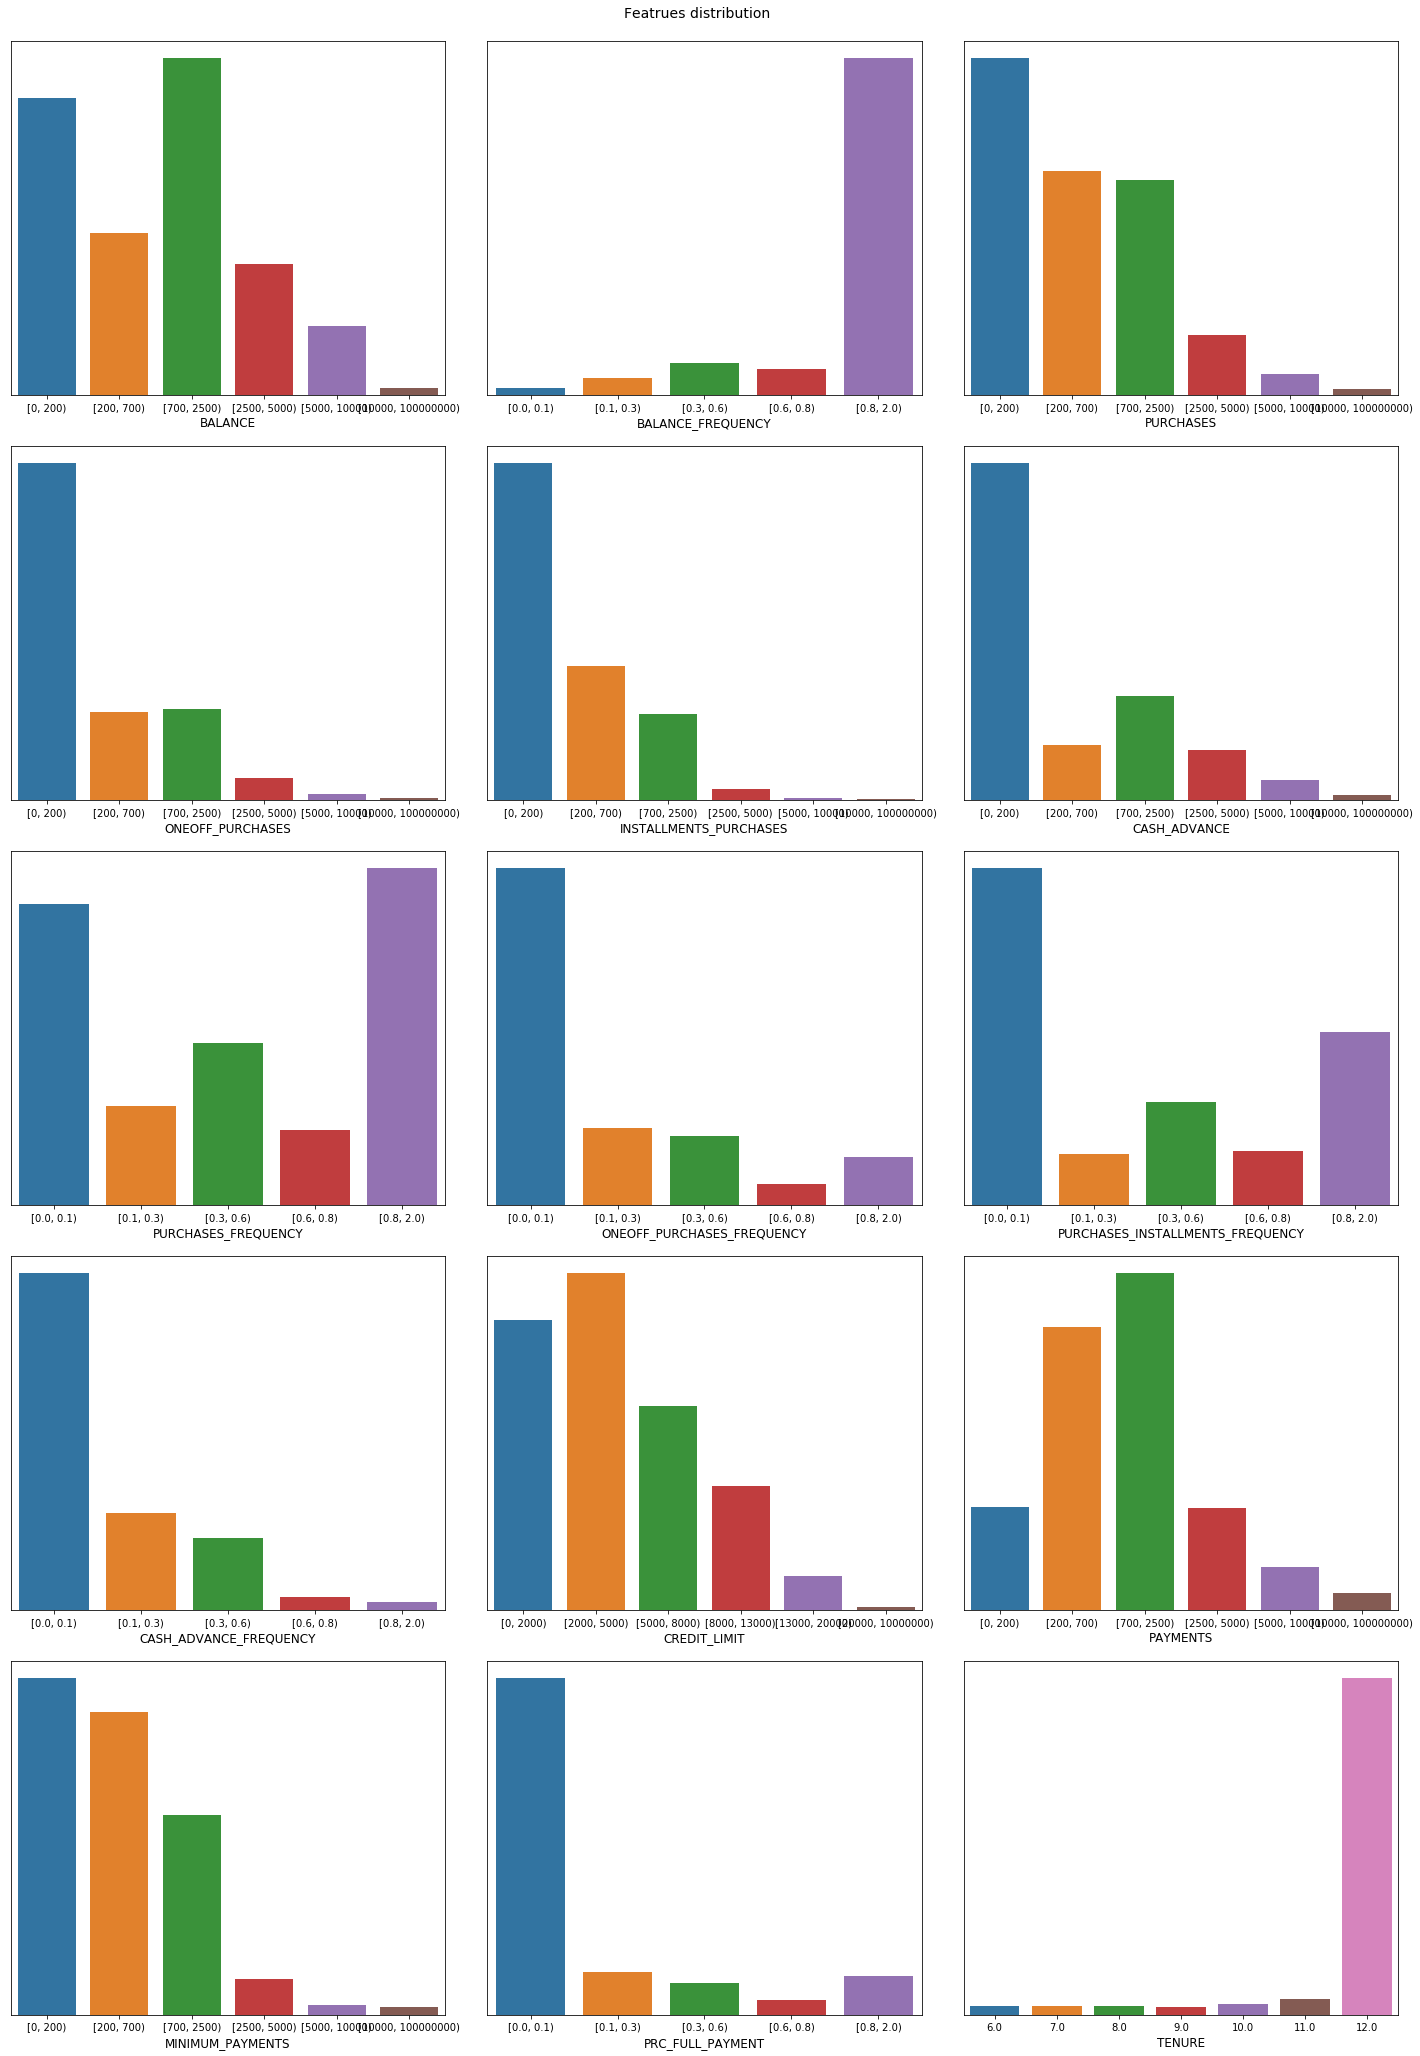

In [46]:
cols = ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES',
       'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
       'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
       'CASH_ADVANCE_FREQUENCY','CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT',
       'TENURE']


fig,axs = plt.subplots(5,3,figsize=(20,28))
plt.suptitle('Featrues distribution',fontsize=14,y=1.01)
axs = axs.flatten()

plt.tight_layout(h_pad=3)
for ind,col in zip(range(len(cols)),cols):
    sns.barplot(pd.value_counts(cc_data_binned[col]).keys(),pd.value_counts(cc_data_binned[col]).values,ax=axs[ind])
    axs[ind].set_yticks(ticks=[])
    axs[ind].set_xlabel(col,fontsize=12)

In [47]:
cc_data_imputed['Kmeans_cluster'] = KMeans(n_clusters=5,init = 'k-means++').fit_predict(cc_data_imputed.to_numpy())


pca = PCA(n_components=2).fit_transform(cc_data_imputed[cc_data_imputed.columns.drop('Kmeans_cluster')])


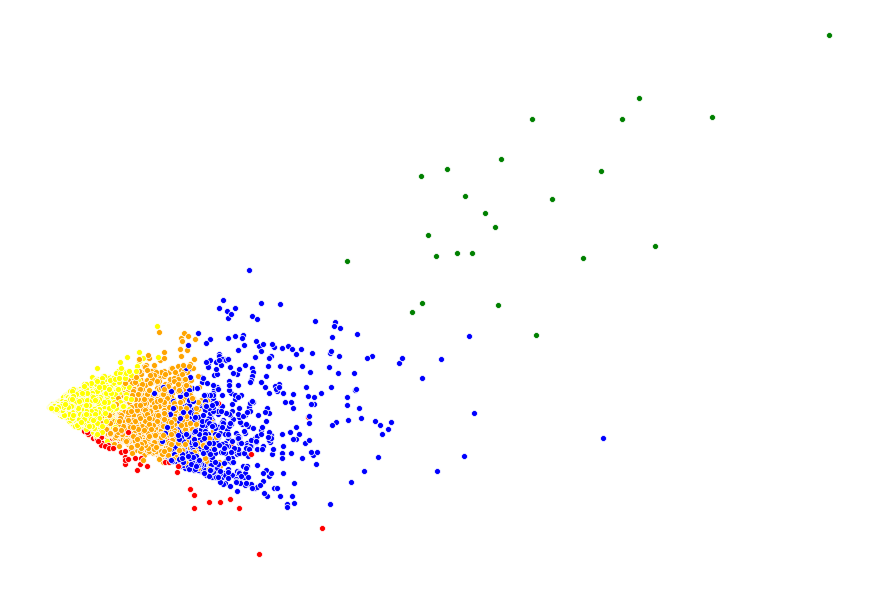

In [48]:
color_dict = {0:'red',1:'yellow',2:'blue',3:'orange',4:'green'}

fig = plt.figure(figsize=(12,8))
ax = fig.add_axes((0,0,1,1))
ax.axis('off')
for i in range(pca.shape[0]):
    sns.scatterplot([pca[i][0]],[pca[i][1]],ax=ax,color=color_dict[cc_data_imputed['Kmeans_cluster'][i]])


     The above clustering though shows the difference decently, still has outliers. Our algorithm had clustered all entries that are far into one cluster(obviously) and this isn't necessarily true. Do you think there will be any difference if we transform the data to some other form?
---

     I don't know! Let's see the difference working with binned data

In [50]:
dummies_df = pd.get_dummies(cc_data_binned[['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
       'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS',
       'BALANCE_FREQUENCY', 'PURCHASES_FREQUENCY',
       'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
       'CASH_ADVANCE_FREQUENCY', 'PRC_FULL_PAYMENT']])

dummies_df[['CASH_ADVANCE_TRX','PURCHASES_TRX', 'TENURE']] = cc_data_imputed[['CASH_ADVANCE_TRX','PURCHASES_TRX', 'TENURE']]


In [51]:
dummies_df['Kmeans_cluster'] = KMeans(n_clusters=5,init = 'k-means++').fit_predict(dummies_df.to_numpy())
pca = PCA(n_components=2).fit_transform(dummies_df[dummies_df.columns.drop('Kmeans_cluster')])


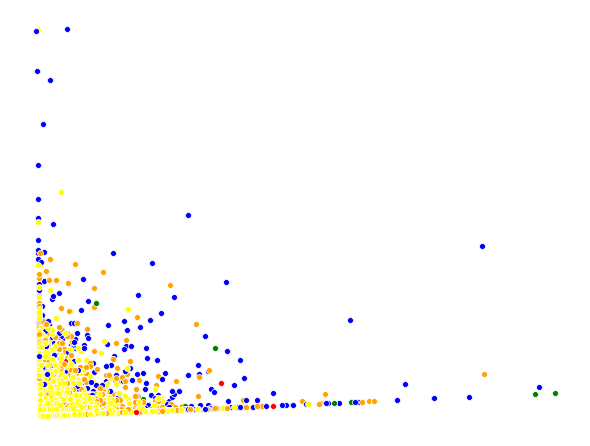

In [52]:
fig = plt.figure(figsize=(8,6))
ax.set_title('Clusters',fontsize=15)
ax = fig.add_axes((0,0,1,1))
ax.axis('off')
for i in range(pca.shape[0]):
    sns.scatterplot([pca[i][0]],[pca[i][1]],ax=ax,color=color_dict[cc_data_imputed['Kmeans_cluster'][i]])


    Using dummy variables, we created a sparse matrix and fed it to our model. The results though specific to individual data points, it's not very intuitive to look at. So, let's use numeric labels to the bins and scale them to get a properly clustered visualization.

In [41]:
cc_data_binned = pd.DataFrame()
for col in norm_cols:
    cc_data_binned[col] = pd.cut(cc_data_imputed[col], bins = [0, 200,700, 2500,5000,10000,10000000],labels=[0,1,2,3,4,5],include_lowest=True)
    
for col in freq_cols:
    cc_data_binned[col] = pd.cut(cc_data_imputed[col],bins = [0, 0.1,0.3,0.6,0.8,2],labels=[0,1,2,3,4],include_lowest=True)
    
cc_data_binned['CREDIT_LIMIT'] = pd.cut(cc_data_imputed['CREDIT_LIMIT'],[0, 2000, 5000,8000,13000,20000,10000000],labels=[0,1,2,3,4,5],include_lowest=True)

cc_data_binned[['CASH_ADVANCE_TRX','PURCHASES_TRX','TENURE']] = cc_data_imputed[['CASH_ADVANCE_TRX','PURCHASES_TRX','TENURE']]

In [57]:
cc_data_binned

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,BALANCE_FREQUENCY,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,PRC_FULL_PAYMENT,CASH_ADVANCE_TRX,PURCHASES_TRX,TENURE
0,0,0,0,0,0,0,1,0,4,1,0,0,0,0,0.0,2.0,12.0
1,3,0,0,0,4,2,3,2,4,0,0,0,1,1,4.0,0.0,12.0
2,2,2,2,0,0,2,1,1,4,4,4,0,0,0,0.0,12.0,12.0
3,2,2,2,0,1,2,0,1,3,0,0,0,0,0,1.0,1.0,12.0
4,2,0,0,0,0,0,1,1,4,0,0,0,0,0,0.0,1.0,12.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,0,1,0,1,0,0,1,0,4,4,0,4,0,2,0.0,6.0,6.0
8946,0,1,0,1,0,0,1,0,4,4,0,4,0,0,0.0,6.0,6.0
8947,0,0,0,0,0,0,0,0,4,4,0,3,0,1,0.0,5.0,6.0
8948,0,0,0,0,0,0,0,0,4,0,0,0,1,1,2.0,0.0,6.0


In [42]:
cc_data_binned_scaled = StandardScaler().fit_transform(cc_data_binned)

In [59]:
cos_sim = 1 - cosine_similarity(cc_data_binned_scaled)
Kmeans_cluster = KMeans(n_clusters=5,init = 'k-means++').fit_predict(cc_data_binned_scaled)
pca = PCA(n_components=2).fit_transform(cos_sim)

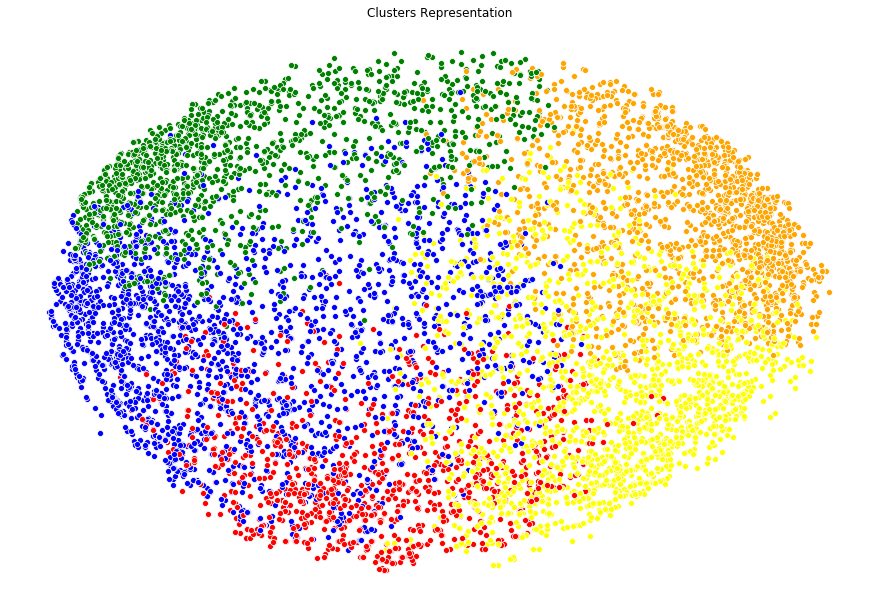

In [60]:
color_dict = {0:'red',1:'yellow',2:'blue',3:'orange',4:'green'}

fig = plt.figure(figsize=(12,8))
ax = fig.add_axes((0,0,1,1))
ax.axis('off')
ax.set_title('Clusters Representation')
for i in range(pca.shape[0]):
    sns.scatterplot([pca[i][0]],[pca[i][1]],ax=ax,color=color_dict[Kmeans_cluster[i]])


    There is a lot of overlap in the clusters, this signifies that our model is not performing very well. But why?
---       

    Remember we used 5 clusters in our model? there is no basis for using exactly 5, it's merely a random number. From the looks, it seems like 2 or 3 clusters are combined to form one. So increasing the number of clusters might make it better.
    Moreover, arbitrarily selecting the number of clusters is not sensible. We can run the Kmeans algorithm multiple times with different number of clusters, plot them as a function of inertia, silhouette_score score and decice on the best number of clusters. 

In [43]:
inertia = list()
silhouette = list()
for cl in range(2,20):
    km_model = KMeans(n_clusters=cl).fit(cc_data_binned_scaled)
    inertia.append(km_model.inertia_)
    silhouette.append(silhouette_score(cc_data_binned_scaled,km_model.labels_))


(2, 20)

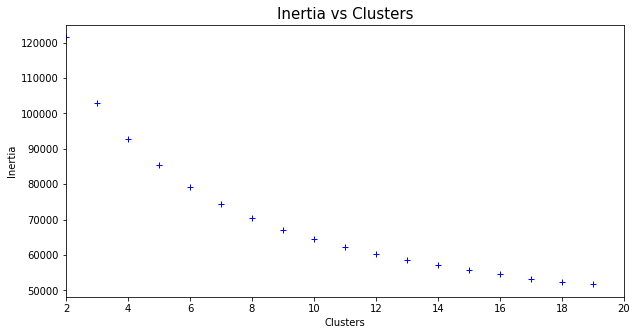

In [52]:
plt.figure(figsize=(10,5))
plt.title('Inertia vs Clusters',fontsize=15)
plt.plot(range(2,20),inertia,'b+')
plt.xlabel('Clusters')
plt.ylabel('Inertia')
plt.xlim(2,20)

(2, 20)

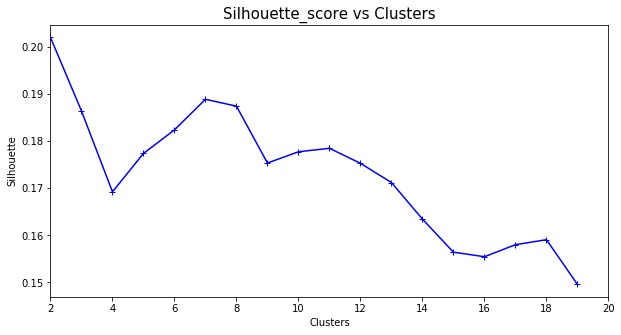

In [54]:
plt.figure(figsize=(10,5))
plt.title('Silhouette_score vs Clusters',fontsize=15)
plt.plot(range(2,20),silhouette,'b+-')
plt.xlabel('Clusters')
plt.ylabel('Silhouette')
plt.xlim(2,20)

    As per the Inertia graph we see an elbow at 7 clusters and per the silhouette graph it's a good option to choose 9 clusters


In [65]:
cc_data_binned_scaled = StandardScaler().fit_transform(cc_data_binned)
Kmeans_cluster = KMeans(n_clusters=9,init = 'k-means++').fit_predict(cc_data_binned_scaled)

cos_sim = 1 - cosine_similarity(cc_data_binned_scaled)
pca = PCA(n_components=2).fit_transform(cos_sim)


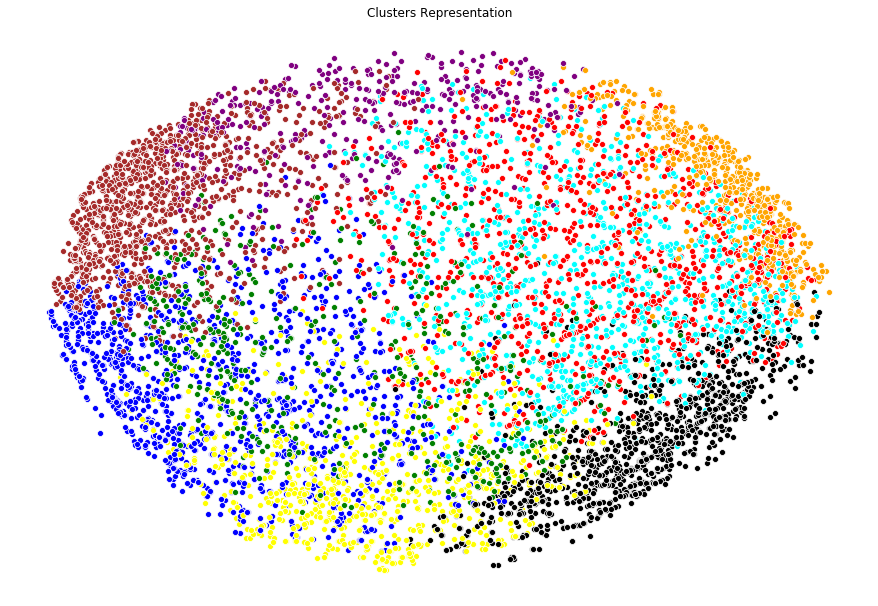

In [66]:
color_dict = {0:'red',1:'yellow',2:'blue',3:'orange',4:'green',5:'purple',6:'black',7:'brown',8:'cyan'}

fig = plt.figure(figsize=(12,8))
ax = fig.add_axes((0,0,1,1))
ax.axis('off')
ax.set_title('Clusters Representation')
for i in range(pca.shape[0]):
    sns.scatterplot([pca[i][0]],[pca[i][1]],ax=ax,color=color_dict[Kmeans_cluster[i]])


    As per the textbook expectation, elbow point of silhouette score and intertia show the optimal number of clusters to group data properly. We had both of those graphs above, and the cluster representation of actual data as well. 
    Do you think we should change the number of clusters and if you do, what # should we use? if you don't think we need to change the # clusters, how do you justify the above scatter plot?
    
    Take a while to think of your answer and a justification. Then go forward
---
     
    9 is not a very good idea due to the overlap in clusters, but let's try other algorithms just to be sure

In [68]:
#spectral clustering
sc = SpectralClustering(n_clusters=9).fit_predict(cc_data_binned_scaled)
cos_sim = 1 - cosine_similarity(cc_data_binned_scaled)
pca = PCA(n_components=2).fit_transform(cos_sim)


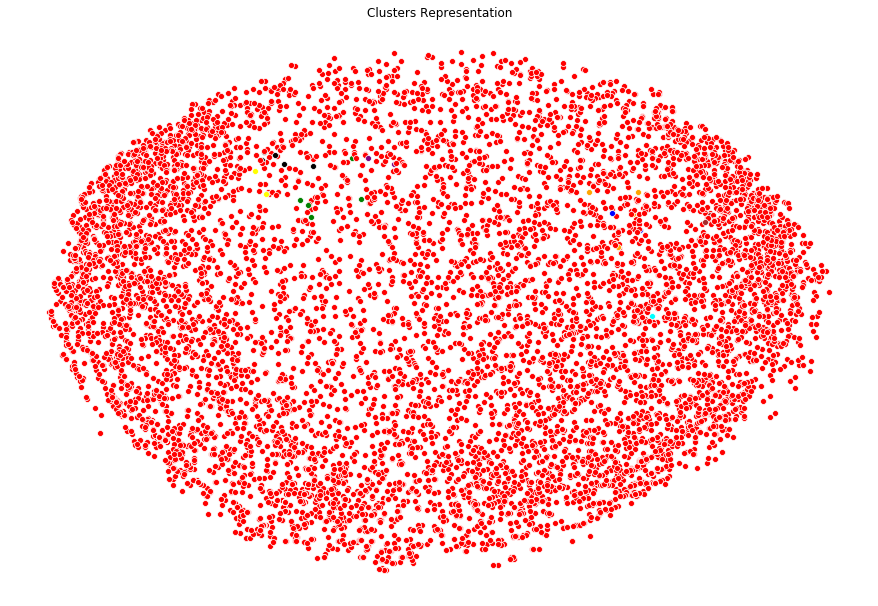

In [69]:
color_dict = {0:'red',1:'yellow',2:'blue',3:'orange',4:'green',5:'purple',6:'black',7:'brown',8:'cyan'}

fig = plt.figure(figsize=(12,8))
ax = fig.add_axes((0,0,1,1))
ax.axis('off')
ax.set_title('Clusters Representation')
for i in range(pca.shape[0]):
    sns.scatterplot([pca[i][0]],[pca[i][1]],ax=ax,color=color_dict[sc[i]])


In [70]:
pd.value_counts(sc)

0    8924
6       5
4       5
3       4
2       3
1       3
7       2
5       2
8       2
dtype: int64

    what do you think happened above? is it expected? what should be our next step?
---
    
    Spectral clustering failed to perfrom well, sometimes it's better to stick to a simpler algorithm since the complex ones might overfit especially when we do not have huge amounts of data

In [71]:
ac = AgglomerativeClustering(n_clusters=9).fit_predict(cc_data_binned_scaled)
cos_sim = 1 - cosine_similarity(cc_data_binned_scaled)
pca = PCA(n_components=2).fit_transform(cos_sim)


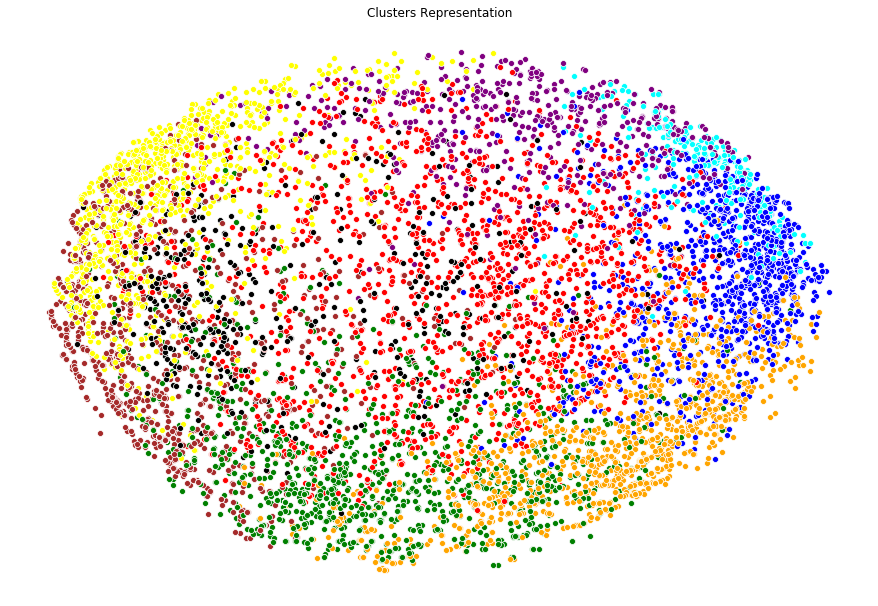

In [72]:
color_dict = {0:'red',1:'yellow',2:'blue',3:'orange',4:'green',5:'purple',6:'black',7:'brown',8:'cyan'}

fig = plt.figure(figsize=(12,8))
ax = fig.add_axes((0,0,1,1))
ax.axis('off')
ax.set_title('Clusters Representation')
for i in range(pca.shape[0]):
    sns.scatterplot([pca[i][0]],[pca[i][1]],ax=ax,color=color_dict[ac[i]])

    The silhouette score curve suggested 9 clusters and hence we have tried 9 but looking at the figure above it doesn't look like 9 is any special number to itemize all points. As per our inertia curve, around 7 looks like a good fit too, let's try that.

In [80]:
cc_data_binned_scaled = StandardScaler().fit_transform(cc_data_binned)
Kmeans_cluster = KMeans(n_clusters=7,init = 'k-means++').fit_predict(cc_data_binned_scaled)

cos_sim = 1 - cosine_similarity(cc_data_binned_scaled)
pca = PCA(n_components=2).fit_transform(cos_sim)


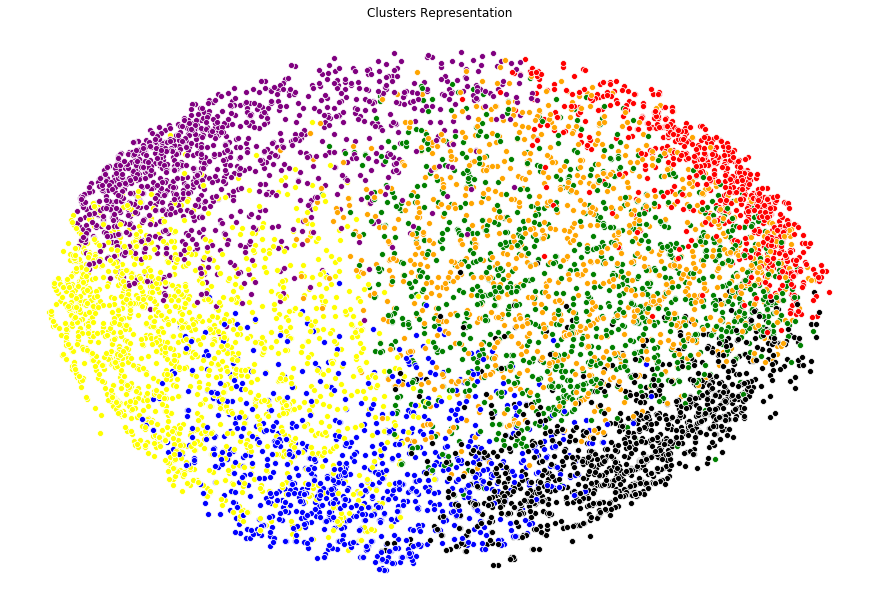

In [75]:
color_dict = {0:'red',1:'yellow',2:'blue',3:'orange',4:'green',5:'purple',6:'black',7:'brown',8:'cyan'}

fig = plt.figure(figsize=(12,8))
ax = fig.add_axes((0,0,1,1))
ax.axis('off')
ax.set_title('Clusters Representation')
for i in range(pca.shape[0]):
    sns.scatterplot([pca[i][0]],[pca[i][1]],ax=ax,color=color_dict[Kmeans_cluster[i]])


    7 surely looks better than 9, but to see if that is the best possible option let's also check with 6. 
    - Try creating a model with only 6 clusters and compare your results with the ones we have till now. Try answering why 6 is a better or worse option than 7.
    
    Let's interpret the results with 7 clusters

In [103]:
cc_data_imputed['Kmeans_cluster'] = Kmeans_cluster

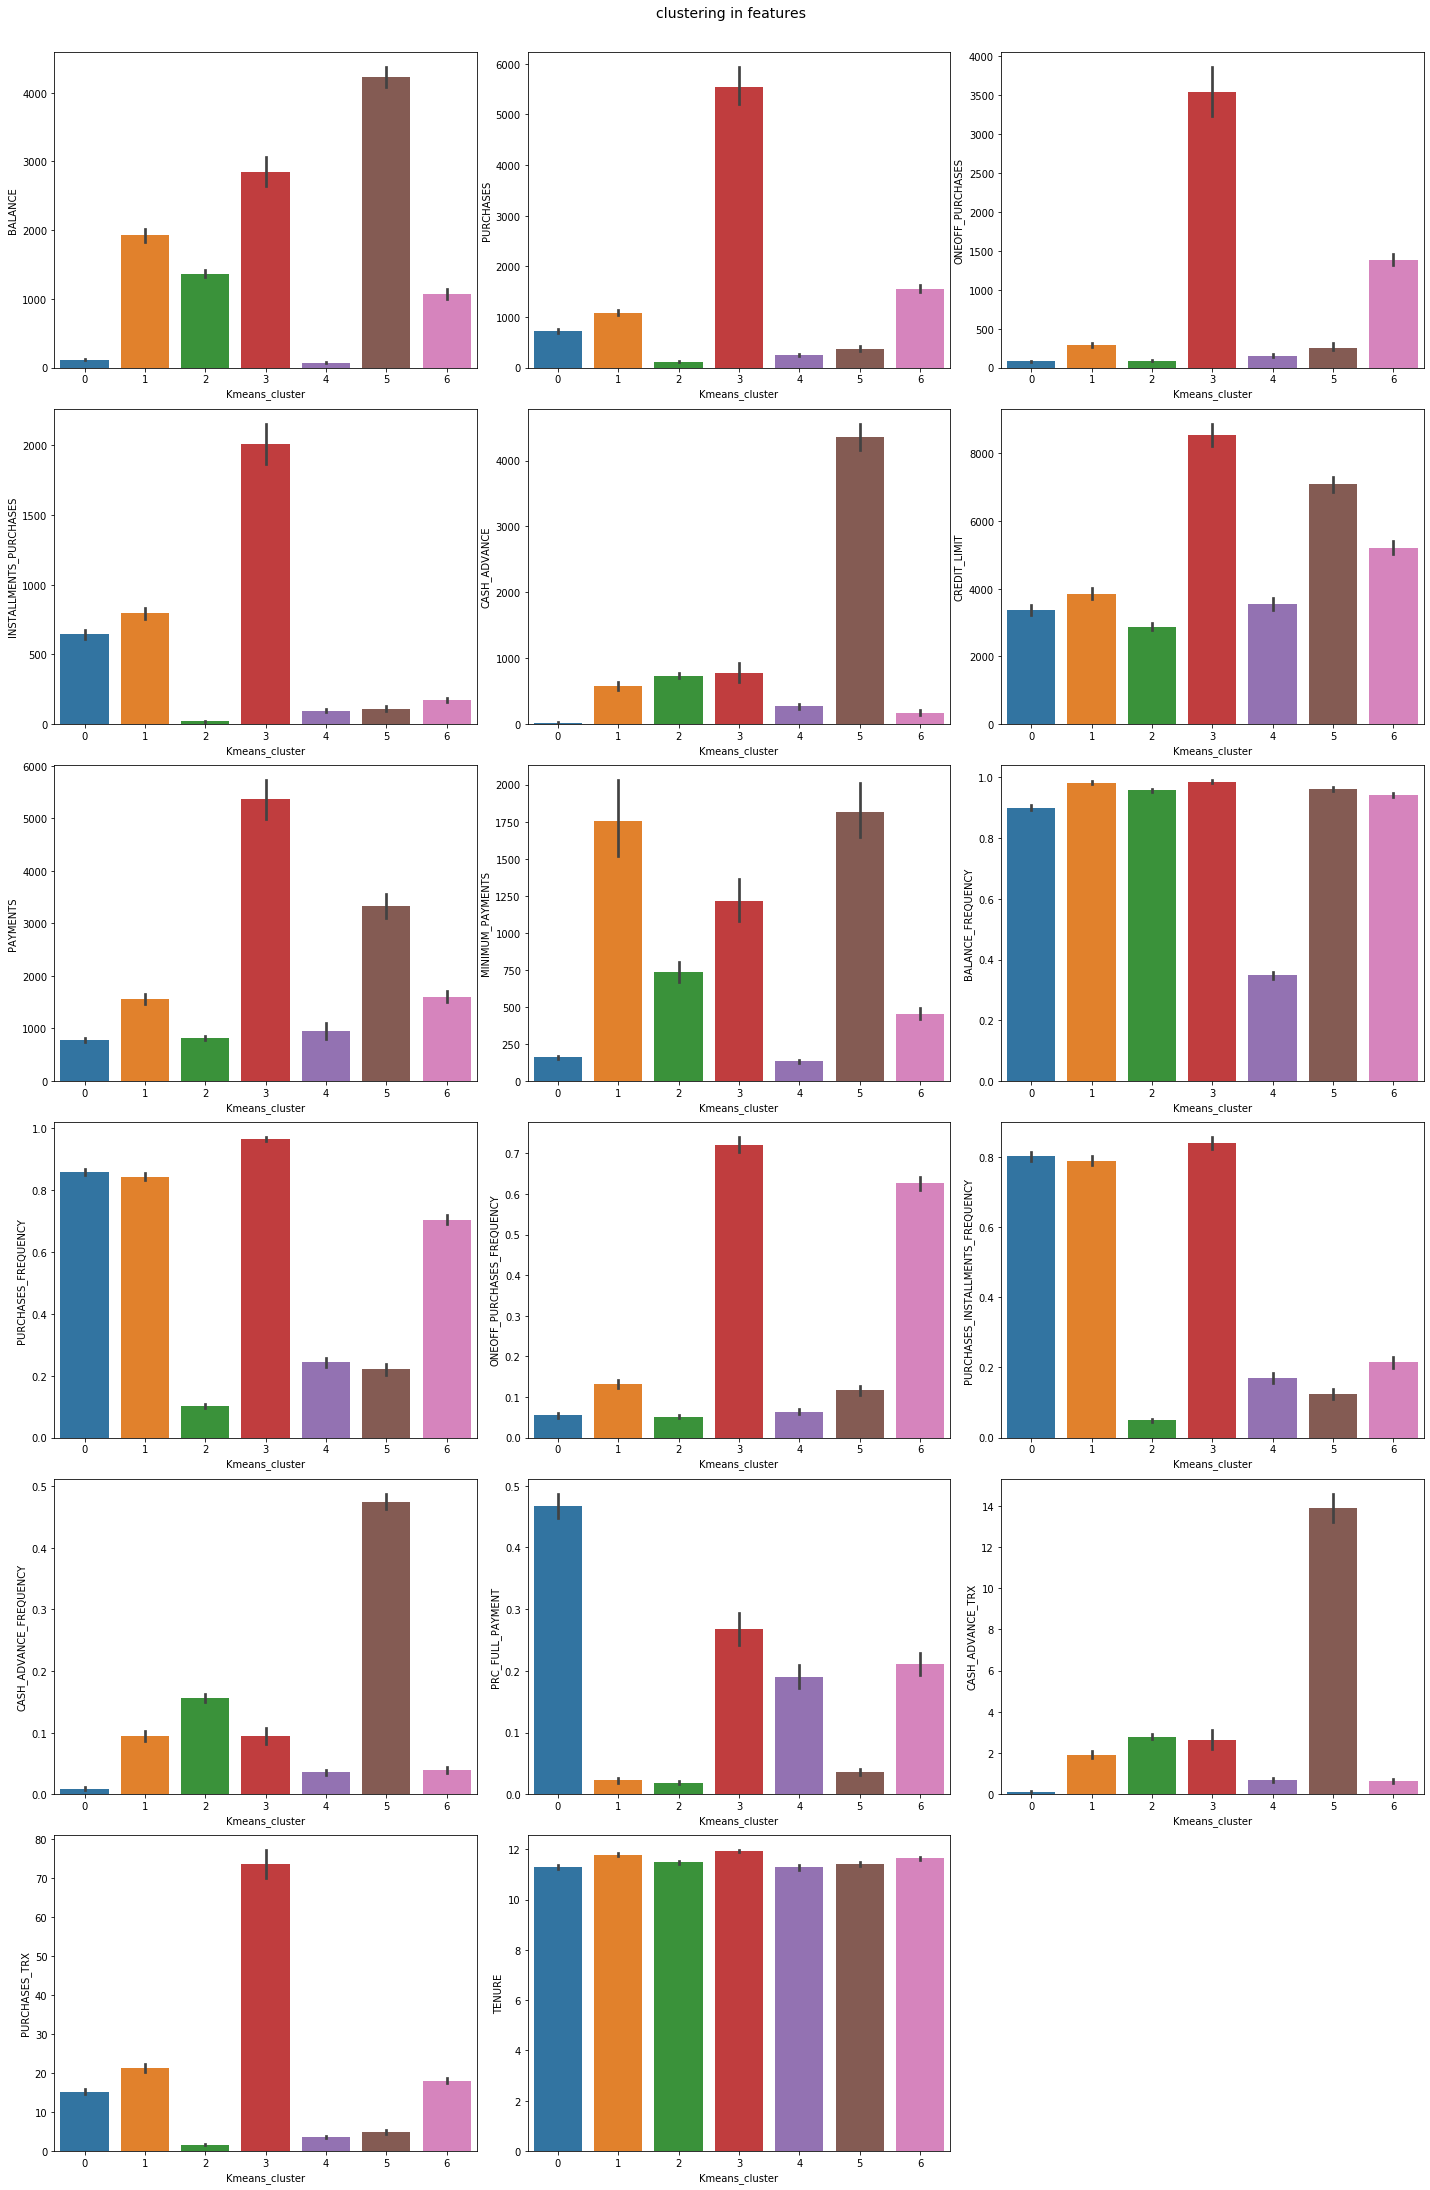

In [106]:
x = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
       'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS',
       'BALANCE_FREQUENCY', 'PURCHASES_FREQUENCY',
       'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
       'CASH_ADVANCE_FREQUENCY', 'PRC_FULL_PAYMENT', 'CASH_ADVANCE_TRX',
       'PURCHASES_TRX', 'TENURE']

fig,ax= plt.subplots(6,3,figsize=(20,30))
fig.suptitle('clustering in features',fontsize=14,y=1.01)
plt.tight_layout(pad=2)
ax = ax.flatten()
ax[-1].axis('off')
for i,col in zip(range(len(x)),x):
    sns.barplot(x='Kmeans_cluster',y=col,data=cc_data_imputed,ax=ax[i])

### Conclusion:
    
    cluster 0: Moderate credit_limit but high purchase frequency and many installment_purchases
    cluster 1: Almost same credit_limit as cluster 0 but higher installment purchases and cash advance, makes it less risky to bet on especially because they have more balance then cluster 0
    cluster 2: Least number of purchases despite moderate balance and credit_limit. This group is not at all risky but also not profitable since they rarely make purchases
    cluster 3: This group is ideal for any credit card company. They have decent balance, makes most purchases(all kinds) and makes payments proportionally. Though this is the ideal group, credit_limit should always be under check since the balance they have is only decent
    cluster 4: This group is very similar to 2, but very less profitable since they make small number of purchases and they also prefer making full payments leaving very less chance for revenue from interest. They also have the least blance_frequency so we can't expect much from this group
    cluster 5: This is the richest group in terms of balance and hence also prefer to pay in cash advance more than any other group. However, they are prone to making minimum payments and hence could be profitable & safe considering the balance
    cluster 6: One of those upper mediocre groups that prefer to be safe than sorry, so the credit offered to them is in safe hands while they also generate revenue by decent spendings
    
    Based on the above qualities of the clusters, we can design effective campaigns to upsell and cross sell services to our customers


*You might not necessarily get the same results when you work on it yourself and that is not a wrong answer. There's really no correct answer or best model, as long as the interpretation of the result makes sense.Our target is to improve the performance and we keep doing it as long as possible*

*To take it to the next step you can try thinking the sort of strategies to apply for customers in different clusters to upsell or cross-sell products*